# Network Intrusion Detection System using Explainable AI (XIDS)
**Runtime > Change runtime type > T4 GPU**, then run the cells top to bottom.

Pipeline: CICFlowMeter CSVs -> clean -> **dataset insights** -> split + scale -> **PSO feature selection** -> train 6 models (XGBoost, Random Forest, MLP, CNN, Transformer, CNN+Transformer) -> **full metrics + curves** -> **SHAP explanations for every model** -> explanation quality + timing -> everything saved to Google Drive.

| Step | What it produces |
|---|---|
| 1-2 | Config, data loading and cleaning |
| 3 | Dataset insight tables and graphs |
| 4 | Split, scaling |
| 5 | Binary PSO feature selection (convergence curve, selected features) |
| 6-7 | Model definitions and training |
| 8 | Accuracy, Precision, Recall, F1, FPR, AUC-ROC, confusion matrices, ROC/PR curves, latency |
| 9 | SHAP for all models, explanation quality (faithfulness, sparsity, stability), explanation time |
| 10 | Final report table and list of saved files |

## 0. Install and imports

In [1]:
%pip -q install shap xgboost

In [2]:
import os, glob, time, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, auc, precision_recall_curve, average_precision_score,
                             confusion_matrix, matthews_corrcoef)
from scipy.stats import spearmanr
from xgboost import XGBClassifier
import shap, joblib
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
SEED = 42
np.random.seed(SEED); tf.random.set_seed(SEED)
rng = np.random.default_rng(SEED)
print('TensorFlow', tf.__version__, '| SHAP', shap.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 | SHAP 0.54.1
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Configuration (edit this cell)

In [3]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR  = '/content/drive/MyDrive/XIDS/data'        # folder with CIC-IDS2017 / CIC-DDoS2019 CSV files
OUT_DIR   = '/content/drive/MyDrive/XIDS/output_v2'    # everything is saved here
LABEL_COL = 'Label'

MAX_PER_CLASS = 60000    # cap rows per class
MIN_PER_CLASS = 20       # drop classes with fewer rows
MERGE_LABELS  = True     # DrDoS_UDP + UDP -> UDP, UDP-lag + UDPLag -> UDPLag, ...

# PSO
RUN_PSO       = True     # False = reuse the mask saved in OUT_DIR from an earlier run
PSO_PARTICLES = 20
PSO_ITERS     = 20
PSO_TRAIN_N   = 20000    # rows used inside the PSO fitness function (keeps it fast)
PSO_VAL_N     = 10000
PSO_ALPHA     = 0.95     # fitness = alpha*macroF1 + (1-alpha)*(1 - selected/total)
PSO_MIN_FEATS = 5

# Deep learning
BATCH_SIZE, EPOCHS = 512, 30
D_MODEL, N_HEADS, N_BLOCKS, FF_DIM = 64, 4, 2, 128

# SHAP
SHAP_PER_CLASS = 10      # explained test samples per class (rows explained = classes x this)
SHAP_BG        = 100     # background samples
TOP_K_DELETE   = 5       # features removed in the faithfulness test

MODEL_DIR, PLOT_DIR, TABLE_DIR, SHAP_DIR = [os.path.join(OUT_DIR, d) for d in ('models', 'plots', 'tables', 'shap')]
for d in (MODEL_DIR, PLOT_DIR, TABLE_DIR, SHAP_DIR): os.makedirs(d, exist_ok=True)

def savefig(name):
    plt.savefig(os.path.join(PLOT_DIR, name), dpi=150, bbox_inches='tight')
def savetab(df, name, index=False):
    df.to_csv(os.path.join(TABLE_DIR, name), index=index)

Mounted at /content/drive


## 2. Load and clean data

In [4]:
files = sorted(glob.glob(os.path.join(DATA_DIR, '**', '*.csv'), recursive=True))
print(len(files), 'CSV files found')
assert files, 'No CSV files found - check DATA_DIR'

frames, file_info = [], []
for f in files:
    df = pd.read_csv(f, low_memory=False)
    df.columns = df.columns.str.strip()
    df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
    if LABEL_COL not in df.columns:
        print('skipping (no label col):', os.path.basename(f)); continue
    y = df[LABEL_COL].astype(str).str.strip()
    X = df.drop(columns=[LABEL_COL]).apply(pd.to_numeric, errors='coerce').astype('float32')
    X[LABEL_COL] = y.values
    frames.append(X)
    file_info.append([os.path.basename(f), len(X), X.shape[1] - 1])

data = pd.concat(frames, ignore_index=True)
del frames
data = data.loc[:, ~data.columns.duplicated()]
if MERGE_LABELS:
    def clean_label(v):
        v = v.replace('DrDoS_', '').replace('-', '').replace(' ', '')
        return 'UDPLag' if v.lower() == 'udplag' else v
    data[LABEL_COL] = data[LABEL_COL].map(clean_label)

feat_cols = [c for c in data.columns if c != LABEL_COL]
# data-quality counts BEFORE cleaning (used in the insights section)
arr = data[feat_cols].to_numpy()
quality = pd.DataFrame({'Feature': feat_cols, 'NaN': np.isnan(arr).sum(0), 'Inf': np.isinf(arr).sum(0)})
del arr

data[feat_cols] = data[feat_cols].replace([np.inf, -np.inf], np.nan)
data = data.dropna(axis=1, how='all')
feat_cols = [c for c in data.columns if c != LABEL_COL]
data[feat_cols] = data[feat_cols].fillna(data[feat_cols].median())
raw_counts = data[LABEL_COL].value_counts()
print('Total rows:', len(data), '| features:', len(feat_cols), '| classes:', len(raw_counts))

1 CSV files found
Total rows: 431371 | features: 77 | classes: 13


## 3. Dataset insights

,File,Rows,Features
0,data.csv,431371,78


,Class,Rows,Share (%)
0,NTP,121368,28.135
1,TFTP,98917,22.931
2,Benign,97831,22.679
3,Syn,49373,11.446
4,UDP,28510,6.609
5,MSSQL,14735,3.416
6,UDPLag,8927,2.069
7,DNS,3669,0.851
8,LDAP,3346,0.776
9,SNMP,2717,0.630


Features with NaN/Inf values: 1


,Feature,NaN,Inf
77,Class,431371,0


,Metric,Value
0,Total rows,431371
1,Features,77
2,Classes,13
3,Largest class,NTP (121368)
4,Smallest class,WebDDoS (51)
5,Imbalance ratio (max/min),2379.8
6,NaN cells (before cleaning),431371
7,Inf cells (before cleaning),0


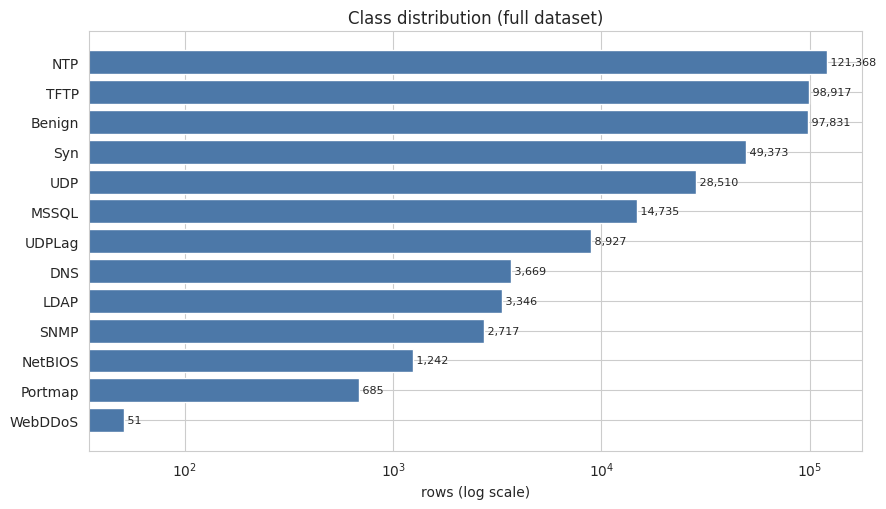

In [5]:
# 3a. Files, class distribution and data quality (full dataset, before capping)
files_tbl = pd.DataFrame(file_info, columns=['File', 'Rows', 'Features'])
display(files_tbl); savetab(files_tbl, 'insight_files.csv')

raw_tbl = raw_counts.rename_axis('Class').reset_index(name='Rows')
raw_tbl['Share (%)'] = (raw_tbl['Rows'] / raw_tbl['Rows'].sum() * 100).round(3)
display(raw_tbl); savetab(raw_tbl, 'insight_class_distribution_raw.csv')

q = quality[(quality.NaN > 0) | (quality.Inf > 0)]
print('Features with NaN/Inf values:', len(q))
if len(q): display(q.sort_values('Inf', ascending=False).head(15))
savetab(quality, 'insight_data_quality.csv')

summary = pd.DataFrame({
    'Metric': ['Total rows', 'Features', 'Classes', 'Largest class', 'Smallest class', 'Imbalance ratio (max/min)',
               'NaN cells (before cleaning)', 'Inf cells (before cleaning)'],
    'Value': [len(data), len(feat_cols), len(raw_counts), f'{raw_counts.index[0]} ({raw_counts.iloc[0]})',
              f'{raw_counts.index[-1]} ({raw_counts.iloc[-1]})', round(raw_counts.iloc[0] / raw_counts.iloc[-1], 1),
              int(quality.NaN.sum()), int(quality.Inf.sum())]})
display(summary); savetab(summary, 'insight_summary.csv')

fig, ax = plt.subplots(figsize=(9, max(4, 0.4 * len(raw_counts))))
ax.barh(raw_counts.index[::-1], raw_counts.values[::-1], color='#4C78A8'); ax.set_xscale('log')
ax.set_xlabel('rows (log scale)'); ax.set_title('Class distribution (full dataset)')
for i, v in enumerate(raw_counts.values[::-1]): ax.text(v, i, f' {v:,}', va='center', fontsize=8)
plt.tight_layout(); savefig('insight_class_distribution_raw.png'); plt.show()

Rows after capping: 293,255 | duplicate rows: 2.75 %
Classes used: 13


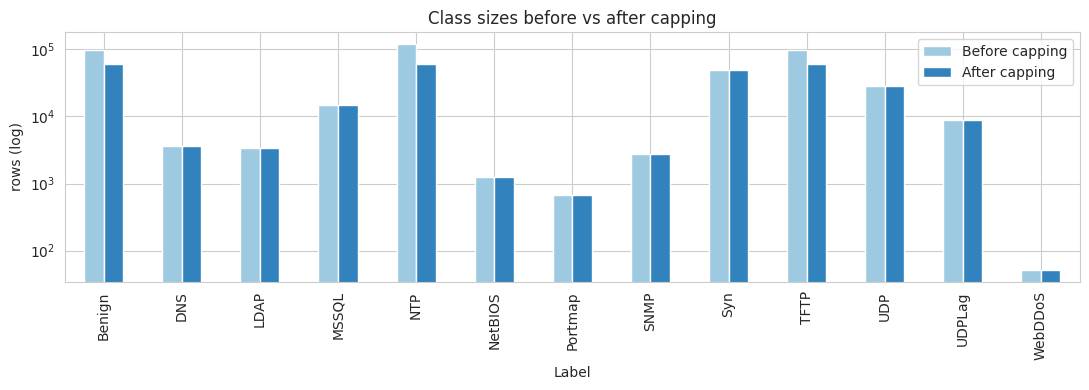

In [6]:
# 3b. Cap big classes, drop tiny ones, keep a sample for EDA graphs
keep = raw_counts[raw_counts >= MIN_PER_CLASS].index
data = data[data[LABEL_COL].isin(keep)]
data = (data.groupby(LABEL_COL, group_keys=False)
            .apply(lambda g: g.sample(min(len(g), MAX_PER_CLASS), random_state=SEED))
            .reset_index(drop=True))
capped_counts = data[LABEL_COL].value_counts()
dup_pct = data.duplicated().mean() * 100
print(f'Rows after capping: {len(data):,} | duplicate rows: {dup_pct:.2f} %')
eda = data.sample(min(50000, len(data)), random_state=SEED).reset_index(drop=True)

le = LabelEncoder()
y = le.fit_transform(data[LABEL_COL])
X = data[feat_cols].values.astype('float32')
class_names = list(le.classes_); n_classes = len(class_names)
del data
print('Classes used:', n_classes)

cmp = pd.DataFrame({'Before capping': raw_counts, 'After capping': capped_counts}).dropna().astype(int)
cmp.plot(kind='bar', figsize=(11, 4), logy=True, color=['#9ecae1', '#3182bd'])
plt.title('Class sizes before vs after capping'); plt.ylabel('rows (log)'); plt.tight_layout()
savefig('insight_capping.png'); plt.show()

Constant features: 12 ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'FIN Flag Count', 'PSH Flag Count', 'ECE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Feature pairs with |corr| > 0.95: 37 (candidates for redundancy removal - PSO handles this)


,Feature A,Feature B,Corr
1,Total Fwd Packets,Subflow Fwd Packets,1.000000
4,Fwd Packets Length Total,Subflow Fwd Bytes,1.000000
3,Total Backward Packets,Subflow Bwd Packets,1.000000
14,Fwd Packet Length Mean,Avg Fwd Segment Size,1.000000
6,Bwd Packets Length Total,Subflow Bwd Bytes,1.000000
15,Bwd Packet Length Mean,Avg Bwd Segment Size,1.000000
27,Fwd PSH Flags,RST Flag Count,1.000000
0,Flow Duration,Fwd IAT Total,0.998309
16,Flow Packets/s,Fwd Packets/s,0.997984
8,Fwd Packet Length Min,Packet Length Min,0.997712


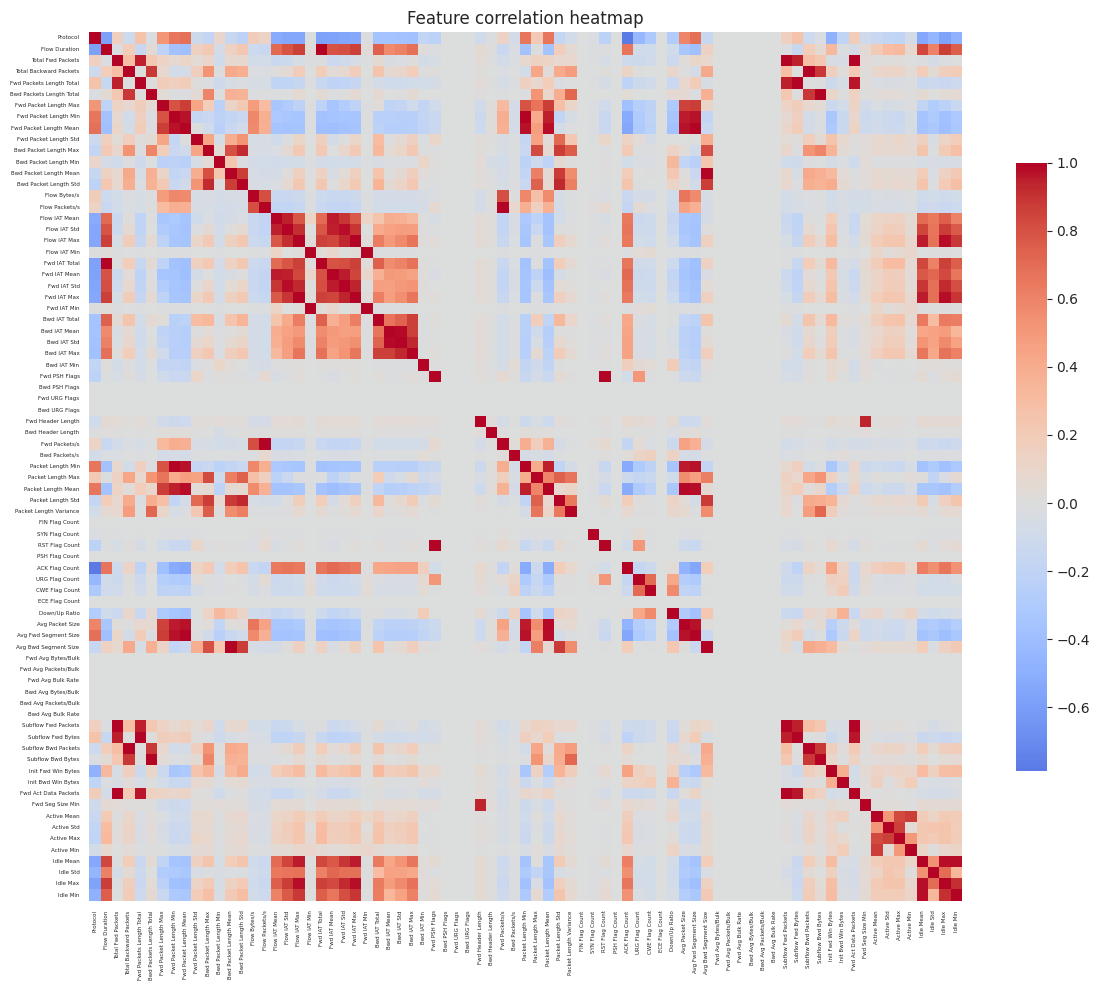

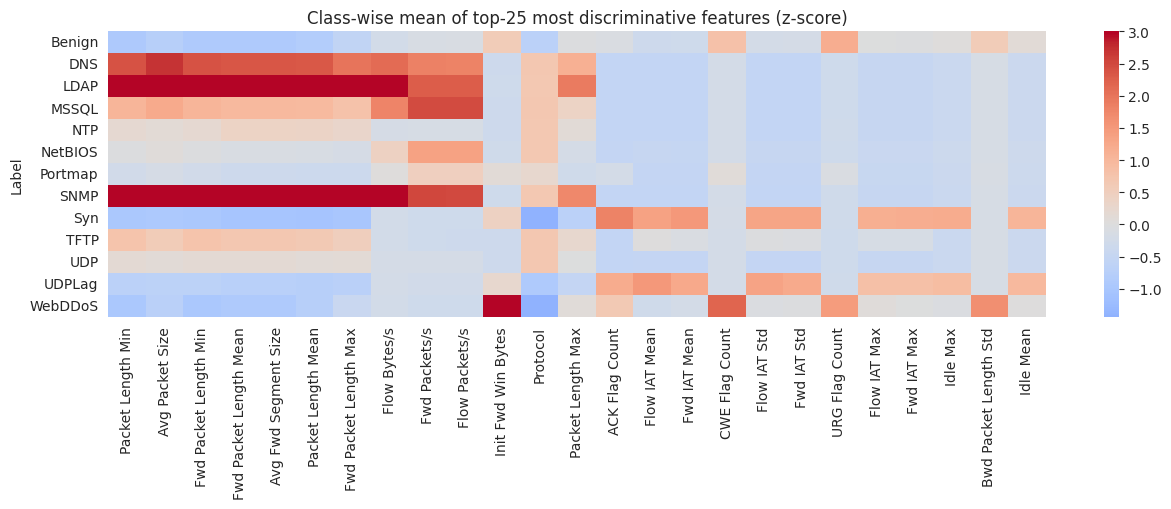

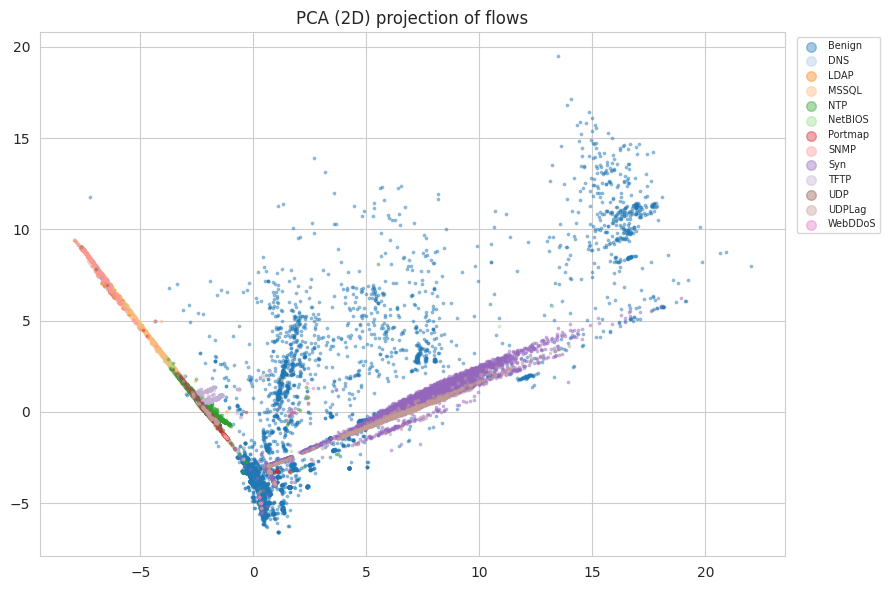

In [7]:
# 3c. Feature insights: constants, correlation, class-wise behaviour, PCA
stds = eda[feat_cols].std()
const_feats = stds[stds == 0].index.tolist()
corr = eda[feat_cols].corr().fillna(0)
upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
hi_pairs = [(a, b, upper.loc[a, b]) for a in upper.index for b in upper.columns
            if pd.notna(upper.loc[a, b]) and abs(upper.loc[a, b]) > 0.95]
print('Constant features:', len(const_feats), const_feats)
print('Feature pairs with |corr| > 0.95:', len(hi_pairs), '(candidates for redundancy removal - PSO handles this)')
hp = pd.DataFrame(hi_pairs, columns=['Feature A', 'Feature B', 'Corr']).sort_values('Corr', key=abs, ascending=False)
savetab(hp, 'insight_high_corr_pairs.csv'); display(hp.head(15))

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap='coolwarm', center=0, xticklabels=True, yticklabels=True, cbar_kws={'shrink': .7})
plt.xticks(fontsize=4); plt.yticks(fontsize=4); plt.title('Feature correlation heatmap'); plt.tight_layout()
savefig('insight_correlation.png'); plt.show()

# class-wise mean of standardised features (which features separate which attacks)
z = (eda[feat_cols] - eda[feat_cols].mean()) / eda[feat_cols].std().replace(0, 1)
z[LABEL_COL] = eda[LABEL_COL].values
cm_mean = z.groupby(LABEL_COL).mean().clip(-3, 3)
top_var = cm_mean.var().sort_values(ascending=False).head(25).index
plt.figure(figsize=(13, max(4, 0.4 * len(cm_mean))))
sns.heatmap(cm_mean[top_var], cmap='coolwarm', center=0, annot=False)
plt.title('Class-wise mean of top-25 most discriminative features (z-score)'); plt.tight_layout()
savefig('insight_class_feature_means.png'); plt.show()

# PCA projection
Z = np.clip(StandardScaler().fit_transform(eda[feat_cols].values), -10, 10)
P2 = PCA(2, random_state=SEED).fit_transform(Z)
plt.figure(figsize=(9, 6))
pal = sns.color_palette('tab20' if n_classes <= 20 else 'husl', n_classes)
for i, c in enumerate(class_names):
    m = eda[LABEL_COL].values == c
    plt.scatter(P2[m, 0], P2[m, 1], s=3, alpha=.4, color=pal[i], label=c)
plt.legend(markerscale=4, bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=7)
plt.title('PCA (2D) projection of flows'); plt.tight_layout(); savefig('insight_pca.png'); plt.show()
del Z, P2, z

## 4. Split and scale (all features; the feature subset is chosen next)

In [8]:
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te   = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
del X, X_tmp

scaler = StandardScaler().fit(X_tr)           # fit on TRAIN only (no leakage)
sc = lambda a: np.clip(scaler.transform(a), -10, 10).astype('float32')
Xtr_all, Xva_all, Xte_all = sc(X_tr), sc(X_va), sc(X_te)
del X_tr, X_va, X_te
print('train', Xtr_all.shape, 'val', Xva_all.shape, 'test', Xte_all.shape)

cw = compute_class_weight('balanced', classes=np.arange(n_classes), y=y_tr)
class_weight = {i: float(w) ** 0.5 for i, w in enumerate(cw)}      # sqrt-damped
sample_w = np.array([class_weight[i] for i in y_tr], dtype='float32')

train (205278, 77) val (43988, 77) test (43989, 77)


## 5. PSO feature selection
Binary PSO: every particle is a 0/1 mask over the features. Velocity update `v = w*v + c1*r1*(pbest-x) + c2*r2*(gbest-x)`, position update `x = 1 if rand < sigmoid(v)`.
Fitness = `alpha * macro-F1 + (1-alpha) * (1 - selected/total)` evaluated with a small Random Forest (fast, and handles unscaled interactions). The best mask is then used by **all** models.

iter 01/20 | best fitness 0.7150 | macro-F1 0.7253 | features 37
iter 02/20 | best fitness 0.7150 | macro-F1 0.7253 | features 37
iter 03/20 | best fitness 0.7150 | macro-F1 0.7253 | features 37
iter 04/20 | best fitness 0.7150 | macro-F1 0.7253 | features 37
iter 05/20 | best fitness 0.7186 | macro-F1 0.7311 | features 40
iter 06/20 | best fitness 0.7186 | macro-F1 0.7311 | features 40
iter 07/20 | best fitness 0.7211 | macro-F1 0.7270 | features 30
iter 08/20 | best fitness 0.7211 | macro-F1 0.7270 | features 30
iter 09/20 | best fitness 0.7211 | macro-F1 0.7270 | features 30
iter 10/20 | best fitness 0.7211 | macro-F1 0.7270 | features 30
iter 11/20 | best fitness 0.7211 | macro-F1 0.7270 | features 30
iter 12/20 | best fitness 0.7211 | macro-F1 0.7270 | features 30
iter 13/20 | best fitness 0.7211 | macro-F1 0.7270 | features 30
iter 14/20 | best fitness 0.7211 | macro-F1 0.7270 | features 30
iter 15/20 | best fitness 0.7211 | macro-F1 0.7270 | features 30
iter 16/20 | best fitness

,#,Selected feature
0,1,Protocol
1,2,Flow Duration
2,3,Total Fwd Packets
3,4,Bwd Packets Length Total
4,5,Bwd Packet Length Min
5,6,Flow IAT Mean
6,7,Fwd IAT Std
7,8,Bwd IAT Mean
8,9,Bwd IAT Max
9,10,Bwd IAT Min


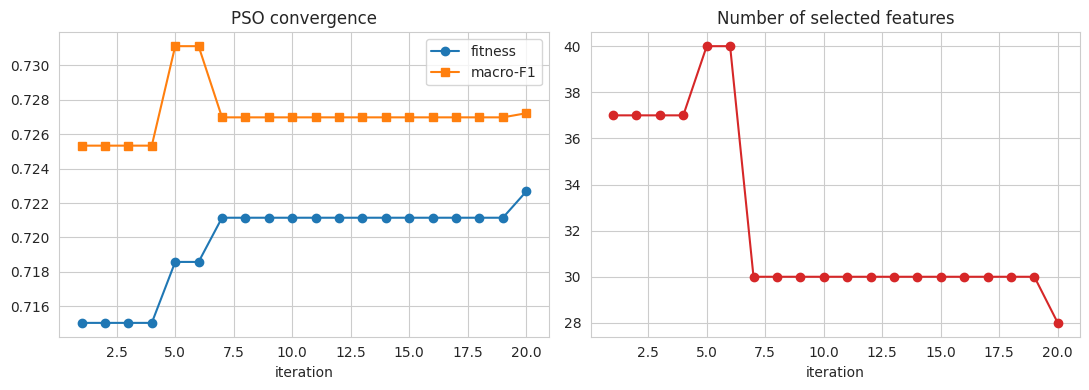

,Feature set,# features,Accuracy (%),Macro-F1,Train time (s)
0,All features,77,96.2400,0.7040,3.3596
1,PSO subset,28,95.9831,0.7019,2.2806


Model input shape: (205278, 28)


In [9]:
def pso_feature_selection(Xt, yt, Xv, yv, n_particles, iters, alpha, min_feats, w_max=0.9, w_min=0.4, c1=1.5, c2=1.5, vmax=4.0):
    F = Xt.shape[1]; cache = {}
    def fitness(mask):
        key = mask.tobytes()
        if key in cache: return cache[key]
        if mask.sum() < min_feats:
            cache[key] = (0.0, 0.0); return cache[key]
        clf = RandomForestClassifier(n_estimators=15, max_depth=12, n_jobs=-1, random_state=SEED).fit(Xt[:, mask], yt)
        f1 = f1_score(yv, clf.predict(Xv[:, mask]), average='macro')
        cache[key] = (alpha * f1 + (1 - alpha) * (1 - mask.sum() / F), f1)
        return cache[key]

    pos = rng.random((n_particles, F)) < 0.5
    pos[0] = True                                   # one particle starts with ALL features (safe baseline)
    vel = rng.uniform(-1, 1, (n_particles, F))
    pbest, pbest_fit = pos.copy(), np.array([fitness(p)[0] for p in pos])
    g = pbest_fit.argmax(); gbest, gbest_fit = pbest[g].copy(), pbest_fit[g]
    hist = []
    for it in range(iters):
        w = w_max - (w_max - w_min) * it / max(1, iters - 1)
        r1, r2 = rng.random((n_particles, F)), rng.random((n_particles, F))
        vel = np.clip(w * vel + c1 * r1 * (pbest.astype(float) - pos) + c2 * r2 * (gbest.astype(float) - pos), -vmax, vmax)
        pos = rng.random((n_particles, F)) < 1 / (1 + np.exp(-vel))
        for i in range(n_particles):
            fit = fitness(pos[i])[0]
            if fit > pbest_fit[i]: pbest[i], pbest_fit[i] = pos[i].copy(), fit
            if fit > gbest_fit: gbest, gbest_fit = pos[i].copy(), fit
        f1_best = fitness(gbest)[1]
        hist.append((it + 1, gbest_fit, f1_best, int(gbest.sum())))
        print(f'iter {it+1:02d}/{iters} | best fitness {gbest_fit:.4f} | macro-F1 {f1_best:.4f} | features {int(gbest.sum())}')
    return gbest, pd.DataFrame(hist, columns=['Iteration', 'Fitness', 'Macro-F1', 'Selected features'])

PSO_MASK_PATH = os.path.join(MODEL_DIR, 'pso_selected_mask.pkl')
if RUN_PSO or not os.path.exists(PSO_MASK_PATH):
    ti = rng.choice(len(Xtr_all), min(PSO_TRAIN_N, len(Xtr_all)), replace=False)
    vi = rng.choice(len(Xva_all), min(PSO_VAL_N, len(Xva_all)), replace=False)
    t0 = time.time()
    mask, pso_hist = pso_feature_selection(Xtr_all[ti], y_tr[ti], Xva_all[vi], y_va[vi],
                                           PSO_PARTICLES, PSO_ITERS, PSO_ALPHA, PSO_MIN_FEATS)
    pso_time = time.time() - t0
    joblib.dump(mask, PSO_MASK_PATH); savetab(pso_hist, 'pso_history.csv')
    print(f'PSO finished in {pso_time:.1f} s')
else:
    mask = joblib.load(PSO_MASK_PATH); pso_hist = pd.read_csv(os.path.join(TABLE_DIR, 'pso_history.csv')); pso_time = None
    print('Loaded saved PSO mask')

sel_idx = np.where(mask)[0]
sel_names = [feat_cols[i] for i in sel_idx]
print(f'PSO selected {len(sel_idx)} of {len(feat_cols)} features')
display(pd.DataFrame({'#': range(1, len(sel_names) + 1), 'Selected feature': sel_names}))
joblib.dump(feat_cols, os.path.join(MODEL_DIR, 'all_feature_columns.pkl'))
joblib.dump(sel_names, os.path.join(MODEL_DIR, 'selected_features.pkl'))
savetab(pd.DataFrame({'Feature': feat_cols, 'Selected': mask}), 'pso_feature_mask.csv')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(pso_hist['Iteration'], pso_hist['Fitness'], marker='o', label='fitness')
ax[0].plot(pso_hist['Iteration'], pso_hist['Macro-F1'], marker='s', label='macro-F1'); ax[0].set_title('PSO convergence'); ax[0].set_xlabel('iteration'); ax[0].legend()
ax[1].plot(pso_hist['Iteration'], pso_hist['Selected features'], marker='o', color='C3'); ax[1].set_title('Number of selected features'); ax[1].set_xlabel('iteration')
plt.tight_layout(); savefig('pso_convergence.png'); plt.show()

# Does PSO help? quick Random Forest on the same 50k rows: all features vs PSO subset
si = rng.choice(len(Xtr_all), min(50000, len(Xtr_all)), replace=False)
rows = []
for nm, cols in [('All features', np.arange(len(feat_cols))), ('PSO subset', sel_idx)]:
    t = time.time(); rf_ = RandomForestClassifier(n_estimators=50, n_jobs=-1, random_state=SEED).fit(Xtr_all[si][:, cols], y_tr[si]); tt = time.time() - t
    pr = rf_.predict(Xte_all[:, cols])
    rows.append([nm, len(cols), accuracy_score(y_te, pr) * 100, f1_score(y_te, pr, average='macro'), tt])
pso_cmp = pd.DataFrame(rows, columns=['Feature set', '# features', 'Accuracy (%)', 'Macro-F1', 'Train time (s)']).round(4)
display(pso_cmp); savetab(pso_cmp, 'pso_vs_all_features.csv')

# apply the PSO subset to every model
X_tr, X_va, X_te = Xtr_all[:, sel_idx], Xva_all[:, sel_idx], Xte_all[:, sel_idx]
del Xtr_all, Xva_all, Xte_all
N_FEAT = X_tr.shape[1]
joblib.dump(scaler, os.path.join(MODEL_DIR, 'scaler_all_features.joblib'))
joblib.dump(le, os.path.join(MODEL_DIR, 'label_encoder.joblib'))
print('Model input shape:', X_tr.shape)

## 6. Model definitions

In [10]:
class PositionEmbedding(layers.Layer):
    def __init__(self, length, dim, **kw):
        super().__init__(**kw); self.length, self.dim = length, dim
        self.emb = layers.Embedding(length, dim)
    def call(self, x):
        return x + self.emb(tf.range(self.length))
    def get_config(self):
        c = super().get_config(); c.update(length=self.length, dim=self.dim); return c

def transformer_block(x, d_model, n_heads, ff_dim, rate=0.1):
    a = layers.MultiHeadAttention(num_heads=n_heads, key_dim=d_model // n_heads)(x, x)
    x = layers.LayerNormalization(epsilon=1e-6)(x + layers.Dropout(rate)(a))
    h = layers.Dense(ff_dim, activation='gelu')(x)
    h = layers.Dense(d_model)(h)
    return layers.LayerNormalization(epsilon=1e-6)(x + layers.Dropout(rate)(h))

def build_cnn_transformer(n_feat, n_classes):
    inp = layers.Input((n_feat, 1))
    x = layers.Conv1D(32, 3, padding='same', activation='relu')(inp); x = layers.BatchNormalization()(x)
    x = layers.Conv1D(D_MODEL, 3, padding='same', activation='relu')(x); x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.1)(x)
    x = PositionEmbedding(n_feat, D_MODEL)(x)
    for _ in range(N_BLOCKS): x = transformer_block(x, D_MODEL, N_HEADS, FF_DIM)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(128, activation='relu')(x); x = layers.Dropout(0.3)(x)
    return keras.Model(inp, layers.Dense(n_classes, activation='softmax')(x), name='XIDS_CNN_Transformer')

def build_cnn(n_feat, n_classes):
    inp = layers.Input((n_feat, 1))
    x = layers.Conv1D(64, 3, padding='same', activation='relu')(inp); x = layers.BatchNormalization()(x)
    x = layers.Conv1D(64, 3, padding='same', activation='relu')(x);   x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(128, 3, padding='same', activation='relu')(x);  x = layers.BatchNormalization()(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(128, activation='relu')(x); x = layers.Dropout(0.3)(x)
    return keras.Model(inp, layers.Dense(n_classes, activation='softmax')(x), name='XIDS_CNN_only')

def build_transformer_only(n_feat, n_classes):
    inp = layers.Input((n_feat, 1))
    x = layers.Dense(D_MODEL)(inp)
    x = PositionEmbedding(n_feat, D_MODEL)(x)
    for _ in range(N_BLOCKS): x = transformer_block(x, D_MODEL, N_HEADS, FF_DIM)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(128, activation='relu')(x); x = layers.Dropout(0.3)(x)
    return keras.Model(inp, layers.Dense(n_classes, activation='softmax')(x), name='XIDS_Transformer_only')

## 7. Train all models (same PSO features, same split)

In [11]:
reg = {}   # name -> dict(type, obj, train_time, predict (batch, 2D -> probs), single (1 flow, 2D -> probs))

def register_sk(name, mdl, fit_fn):
    t = time.time(); fit_fn(); tt = time.time() - t
    reg[name] = dict(type='sk', obj=mdl, train_time=tt, predict=mdl.predict_proba, single=mdl.predict_proba)
    joblib.dump(mdl, os.path.join(MODEL_DIR, name.lower().replace(' ', '_') + '.joblib'), compress=3)
    print(f'{name}: trained in {tt:.1f} s')

xgb_args = dict(n_estimators=300, max_depth=8, learning_rate=0.1, tree_method='hist', n_jobs=-1, random_state=SEED)
try:
    xgb = XGBClassifier(device='cuda', **xgb_args)
    register_sk('XGBoost', xgb, lambda: xgb.fit(X_tr, y_tr, sample_weight=sample_w))
except Exception as e:
    print('GPU XGBoost failed, using CPU:', e)
    xgb = XGBClassifier(device='cpu', **xgb_args)
    register_sk('XGBoost', xgb, lambda: xgb.fit(X_tr, y_tr, sample_weight=sample_w))

rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, class_weight='balanced_subsample', random_state=SEED)
register_sk('Random Forest', rf, lambda: rf.fit(X_tr, y_tr))

mlp = MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True, max_iter=60, random_state=SEED)
register_sk('MLP', mlp, lambda: mlp.fit(X_tr, y_tr))

XGBoost: trained in 14.4 s
Random Forest: trained in 28.9 s
MLP: trained in 91.5 s


Epoch 1/30
401/401 - 28s - 71ms/step - accuracy: 0.9261 - loss: 0.4055 - val_accuracy: 0.4132 - val_loss: 5.2985 - learning_rate: 0.0010
Epoch 2/30
401/401 - 4s - 11ms/step - accuracy: 0.9518 - loss: 0.2815 - val_accuracy: 0.9556 - val_loss: 0.1477 - learning_rate: 0.0010
Epoch 3/30
401/401 - 2s - 6ms/step - accuracy: 0.9544 - loss: 0.2662 - val_accuracy: 0.9525 - val_loss: 0.1590 - learning_rate: 0.0010
Epoch 4/30
401/401 - 2s - 6ms/step - accuracy: 0.9552 - loss: 0.2597 - val_accuracy: 0.9534 - val_loss: 0.1606 - learning_rate: 0.0010
Epoch 5/30

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
401/401 - 2s - 6ms/step - accuracy: 0.9564 - loss: 0.2538 - val_accuracy: 0.9527 - val_loss: 0.1498 - learning_rate: 0.0010
Epoch 6/30
401/401 - 3s - 7ms/step - accuracy: 0.9581 - loss: 0.2440 - val_accuracy: 0.9590 - val_loss: 0.1327 - learning_rate: 5.0000e-04
Epoch 7/30
401/401 - 2s - 6ms/step - accuracy: 0.9584 - loss: 0.2406 - val_accuracy: 0.9591 - val_loss: 0.

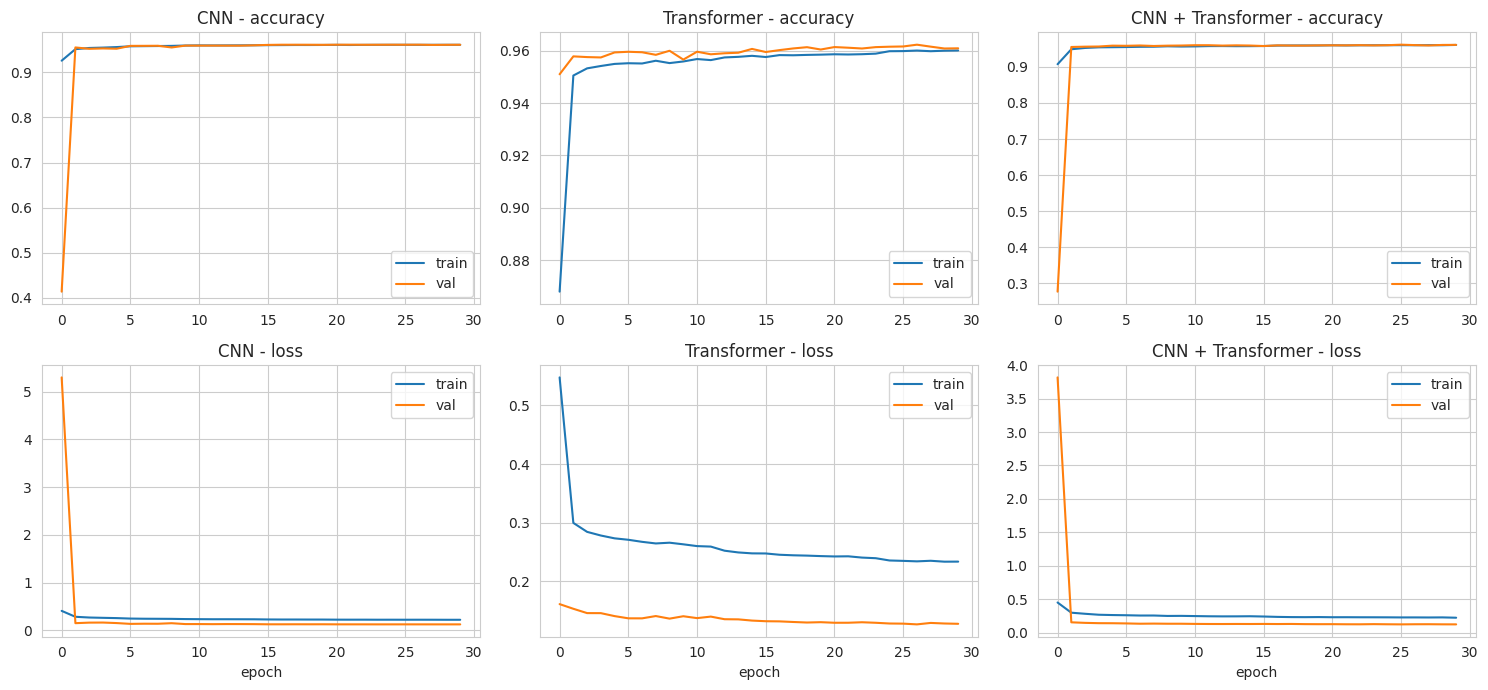

['/content/drive/MyDrive/XIDS/output_v2/models/dl_histories.joblib']

In [12]:
X_tr3, X_va3 = X_tr[..., None], X_va[..., None]

def train_dl(name, tag, builder):
    m = builder(N_FEAT, n_classes)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    cbs = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5, verbose=1),
           keras.callbacks.ModelCheckpoint(os.path.join(MODEL_DIR, f'best_{tag}.keras'), monitor='val_loss', save_best_only=True)]
    t = time.time()
    h = m.fit(X_tr3, y_tr, validation_data=(X_va3, y_va), epochs=EPOCHS, batch_size=BATCH_SIZE,
              class_weight=class_weight, callbacks=cbs, verbose=2)
    tt = time.time() - t
    m.save(os.path.join(MODEL_DIR, f'{tag}.keras'))
    reg[name] = dict(type='dl', obj=m, train_time=tt, history=h.history,
                     predict=lambda A, m=m: m.predict(A[..., None], batch_size=4096, verbose=0),
                     single=lambda A, m=m: m(A[..., None], training=False).numpy())
    print(f'{name}: trained in {tt:.1f} s ({len(h.history["loss"])} epochs)')

train_dl('CNN', 'xids_cnn', build_cnn)
train_dl('Transformer', 'xids_transformer', build_transformer_only)
train_dl('CNN + Transformer', 'xids_cnn_transformer', build_cnn_transformer)

# learning curves of the deep models
dl_names = [n for n in reg if reg[n]['type'] == 'dl']
fig, ax = plt.subplots(2, len(dl_names), figsize=(5 * len(dl_names), 7))
for j, n in enumerate(dl_names):
    h = reg[n]['history']
    ax[0, j].plot(h['accuracy'], label='train'); ax[0, j].plot(h['val_accuracy'], label='val'); ax[0, j].set_title(f'{n} - accuracy'); ax[0, j].legend()
    ax[1, j].plot(h['loss'], label='train'); ax[1, j].plot(h['val_loss'], label='val'); ax[1, j].set_title(f'{n} - loss'); ax[1, j].set_xlabel('epoch'); ax[1, j].legend()
plt.tight_layout(); savefig('training_curves_dl.png'); plt.show()
joblib.dump({n: reg[n]['history'] for n in dl_names}, os.path.join(MODEL_DIR, 'dl_histories.joblib'))

## 8. Evaluation on the unseen test set
Metrics per model: **Accuracy, Precision, Recall, F1, False Positive Rate, AUC-ROC (one-vs-rest), Confusion Matrix**, plus MCC, per-flow inference latency, ROC and Precision-Recall curves.
Multi-class Precision / Recall / F1 / FPR / AUC are reported as **macro** averages (every class counts equally, fair for rare attacks); weighted versions of P/R/F1 are included too.
If a `BENIGN` class exists, the binary view (attack vs benign) detection rate and FPR are added.

In [13]:
Y_onehot = np.eye(n_classes)[y_te]
benign = [i for i, c in enumerate(class_names) if c.lower() in ('benign', 'normal')]

def measure_latency(single_fn, A, n=200):
    idx = rng.choice(len(A), min(n, len(A)), replace=False)
    single_fn(A[:1])                                   # warm-up
    ts = []
    for i in idx:
        t = time.perf_counter(); single_fn(A[i:i + 1]); ts.append((time.perf_counter() - t) * 1000)
    return float(np.mean(ts)), float(np.median(ts)), float(np.percentile(ts, 95))

def evaluate(name):
    r = reg[name]
    P = r['predict'](X_te).astype('float64'); P = P / P.sum(1, keepdims=True)
    yp = P.argmax(1)
    cm = confusion_matrix(y_te, yp, labels=np.arange(n_classes))
    FP = cm.sum(0) - np.diag(cm); FN = cm.sum(1) - np.diag(cm); TP = np.diag(cm); TN = cm.sum() - (FP + FN + TP)
    fpr_c = FP / np.maximum(FP + TN, 1)
    auc_c = np.array([roc_auc_score(Y_onehot[:, c], P[:, c]) for c in range(n_classes)])
    prec_c = precision_score(y_te, yp, labels=np.arange(n_classes), average=None, zero_division=0)
    rec_c = recall_score(y_te, yp, labels=np.arange(n_classes), average=None, zero_division=0)
    f1_c = f1_score(y_te, yp, labels=np.arange(n_classes), average=None, zero_division=0)
    lat = measure_latency(r['single'], X_te)
    res = {'Model': name,
           'Accuracy (%)': accuracy_score(y_te, yp) * 100,
           'Precision (macro)': prec_c.mean(), 'Recall (macro)': rec_c.mean(), 'F1 (macro)': f1_c.mean(),
           'Precision (weighted)': precision_score(y_te, yp, average='weighted', zero_division=0),
           'Recall (weighted)': recall_score(y_te, yp, average='weighted', zero_division=0),
           'F1 (weighted)': f1_score(y_te, yp, average='weighted', zero_division=0),
           'FPR (macro)': fpr_c.mean(), 'AUC-ROC (macro OvR)': auc_c.mean(),
           'MCC': matthews_corrcoef(y_te, yp),
           'Train time (s)': r['train_time'], 'Inference ms/flow': lat[0], 'Latency median (ms)': lat[1], 'Latency p95 (ms)': lat[2]}
    if benign:
        b = benign[0]; ta, pa = y_te != b, yp != b
        res['Binary detection rate (%)'] = (ta & pa).sum() / max(ta.sum(), 1) * 100
        res['Binary FPR (%)'] = (~ta & pa).sum() / max((~ta).sum(), 1) * 100
    pc = pd.DataFrame({'Model': name, 'Class': class_names, 'Precision': prec_c, 'Recall': rec_c, 'F1': f1_c,
                       'FPR': fpr_c, 'AUC-ROC': auc_c, 'Support': cm.sum(1)})
    return res, pc, cm, P

results, per_class, CMS, PROBS = [], [], {}, {}
for n in reg:
    res, pc, cm, P = evaluate(n)
    results.append(res); per_class.append(pc); CMS[n] = cm; PROBS[n] = P
    print(f'{n:18s} acc {res["Accuracy (%)"]:.3f} % | F1-macro {res["F1 (macro)"]:.4f} | FPR {res["FPR (macro)"]:.5f} | AUC {res["AUC-ROC (macro OvR)"]:.4f} | {res["Inference ms/flow"]:.2f} ms/flow')

results_df = pd.DataFrame(results).sort_values('Accuracy (%)', ascending=False).reset_index(drop=True)
per_class_df = pd.concat(per_class, ignore_index=True)
display(results_df.round(4))
savetab(results_df.round(5), 'metrics_all_models.csv'); savetab(per_class_df.round(5), 'metrics_per_class.csv')
np.savez_compressed(os.path.join(TABLE_DIR, 'test_probabilities.npz'), y_true=y_te, classes=np.array(class_names),
                    **{n.replace(' ', '_').replace('+', 'plus'): p.astype('float32') for n, p in PROBS.items()})
best_model = results_df.loc[results_df['F1 (macro)'].idxmax(), 'Model']
print('Best model by macro-F1:', best_model)

XGBoost            acc 96.485 % | F1-macro 0.7358 | FPR 0.00283 | AUC 0.9969 | 15.62 ms/flow
Random Forest      acc 95.758 % | F1-macro 0.6943 | FPR 0.00343 | AUC 0.9708 | 31.06 ms/flow
MLP                acc 96.147 % | F1-macro 0.6771 | FPR 0.00314 | AUC 0.9928 | 0.19 ms/flow
CNN                acc 96.104 % | F1-macro 0.7250 | FPR 0.00315 | AUC 0.9946 | 19.63 ms/flow
Transformer        acc 96.133 % | F1-macro 0.7179 | FPR 0.00314 | AUC 0.9938 | 59.21 ms/flow
CNN + Transformer  acc 96.056 % | F1-macro 0.7208 | FPR 0.00319 | AUC 0.9948 | 49.06 ms/flow


,Model,Accuracy (%),Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),FPR (macro),AUC-ROC (macro OvR),MCC,Train time (s),Inference ms/flow,Latency median (ms),Latency p95 (ms),Binary detection rate (%),Binary FPR (%)
0,XGBoost,96.4855,0.7339,0.7401,0.7358,0.9652,0.9649,0.9648,0.0028,0.9969,0.9578,14.4060,15.6221,14.6509,23.1409,99.9400,0.1111
1,MLP,96.1468,0.7055,0.6894,0.6771,0.9608,0.9615,0.9586,0.0031,0.9928,0.9538,91.5396,0.1901,0.1829,0.2488,99.7971,0.4667
2,Transformer,96.1331,0.7366,0.7426,0.7179,0.9624,0.9613,0.9595,0.0031,0.9938,0.9537,206.1783,59.2099,38.1869,206.3249,99.7228,0.3444
3,CNN,96.1036,0.7254,0.7495,0.7250,0.9617,0.9610,0.9598,0.0032,0.9946,0.9533,107.1013,19.6311,18.9551,24.0200,99.7999,0.4333
4,CNN + Transformer,96.0558,0.7288,0.7445,0.7208,0.9614,0.9606,0.9590,0.0032,0.9948,0.9528,223.1361,49.0571,44.9720,67.1925,99.7914,0.3778
5,Random Forest,95.7580,0.6924,0.6967,0.6943,0.9577,0.9576,0.9576,0.0034,0.9708,0.9491,28.9137,31.0647,33.0572,48.7298,99.8971,0.1778


Best model by macro-F1: XGBoost


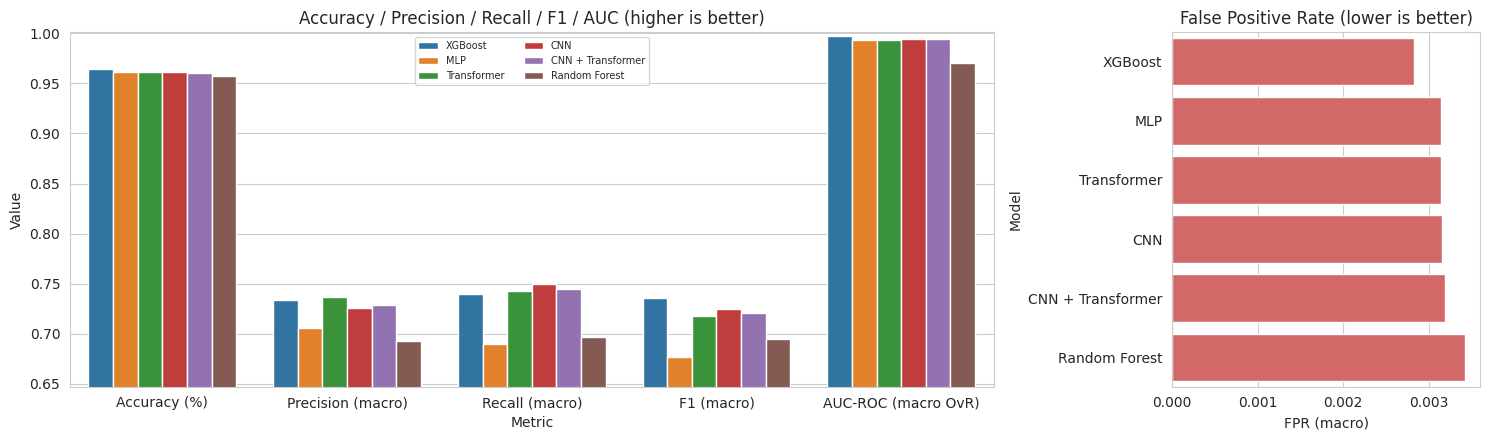

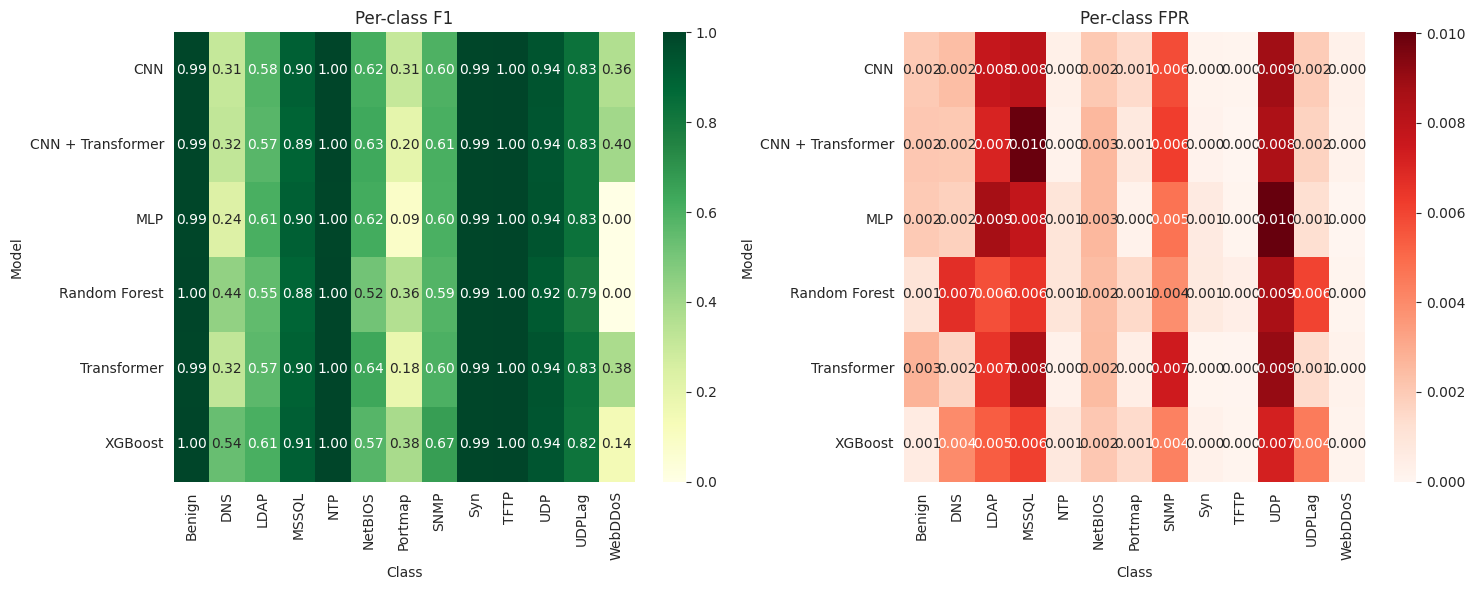

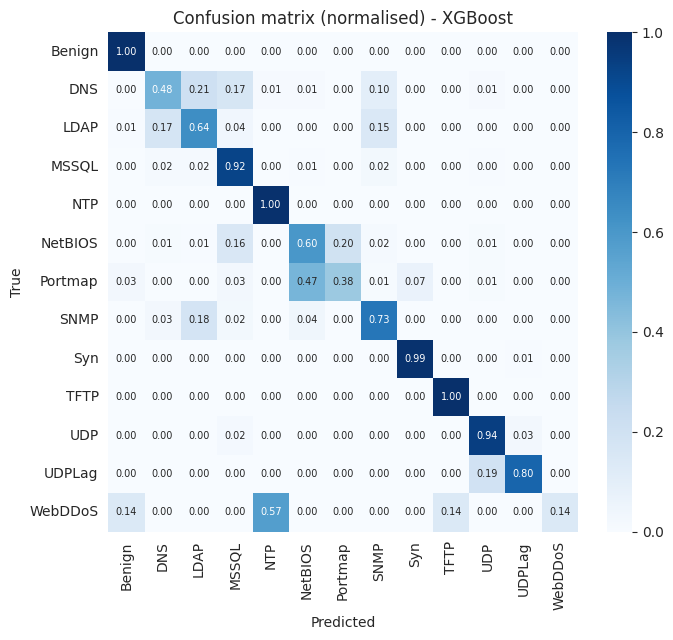

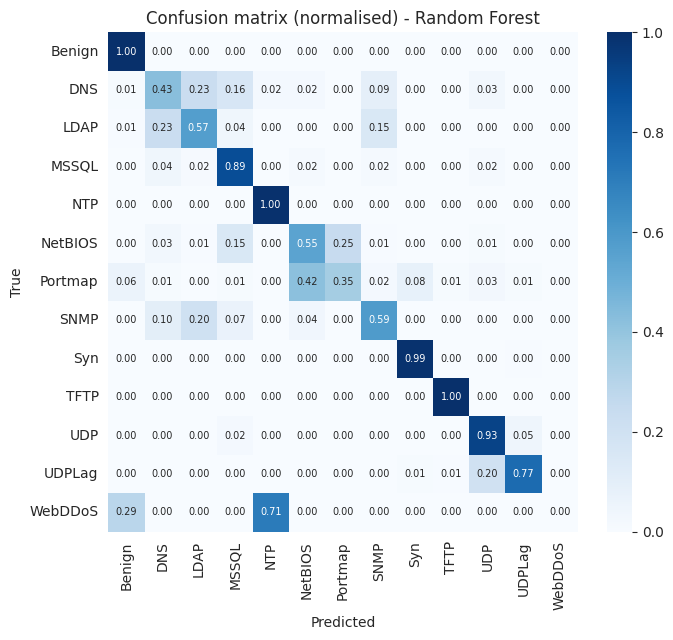

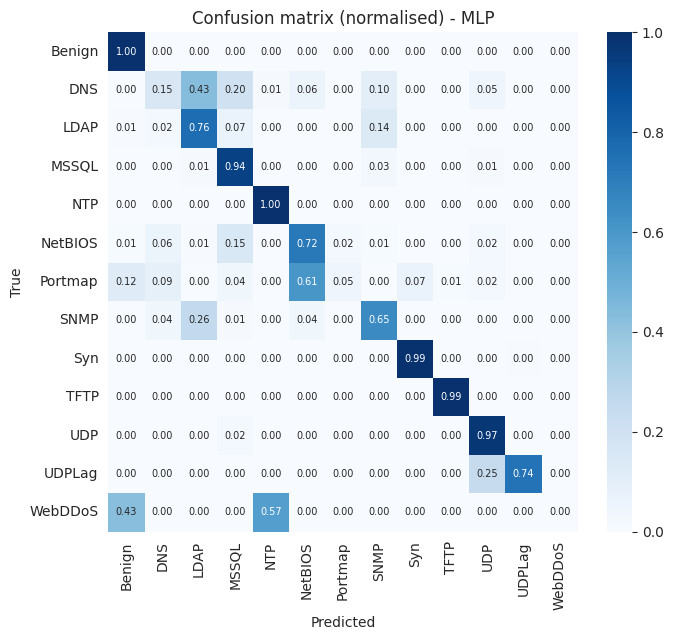

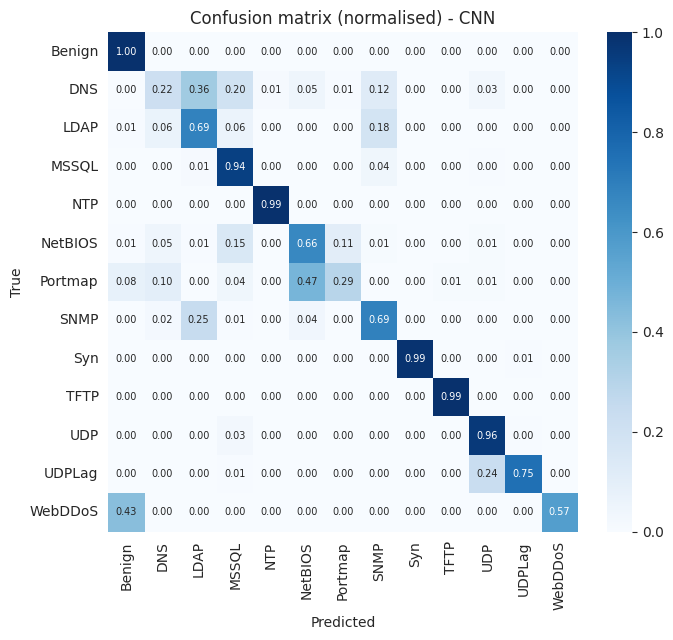

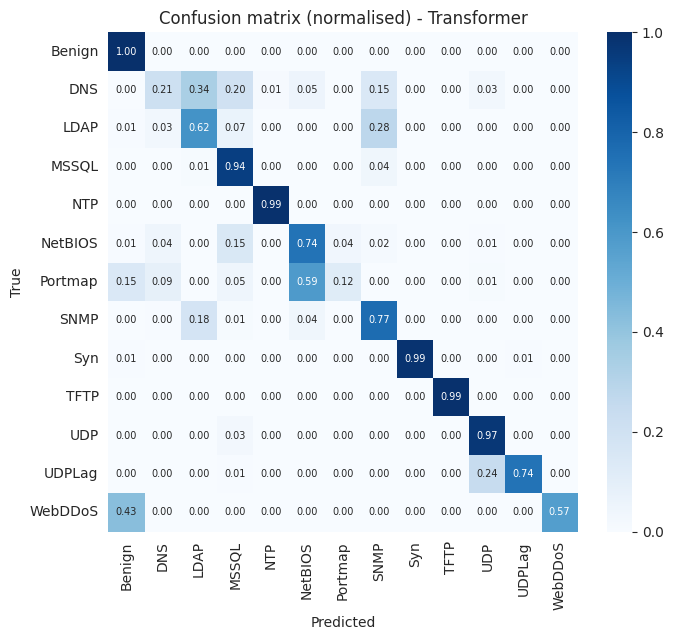

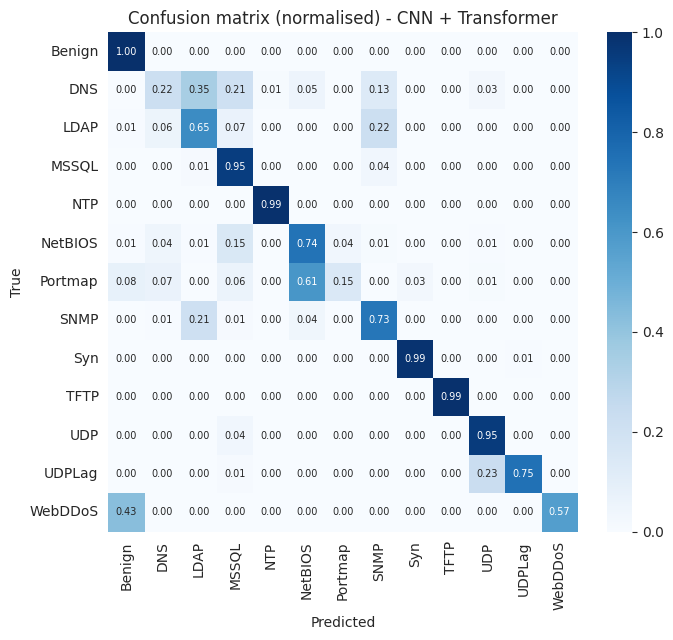

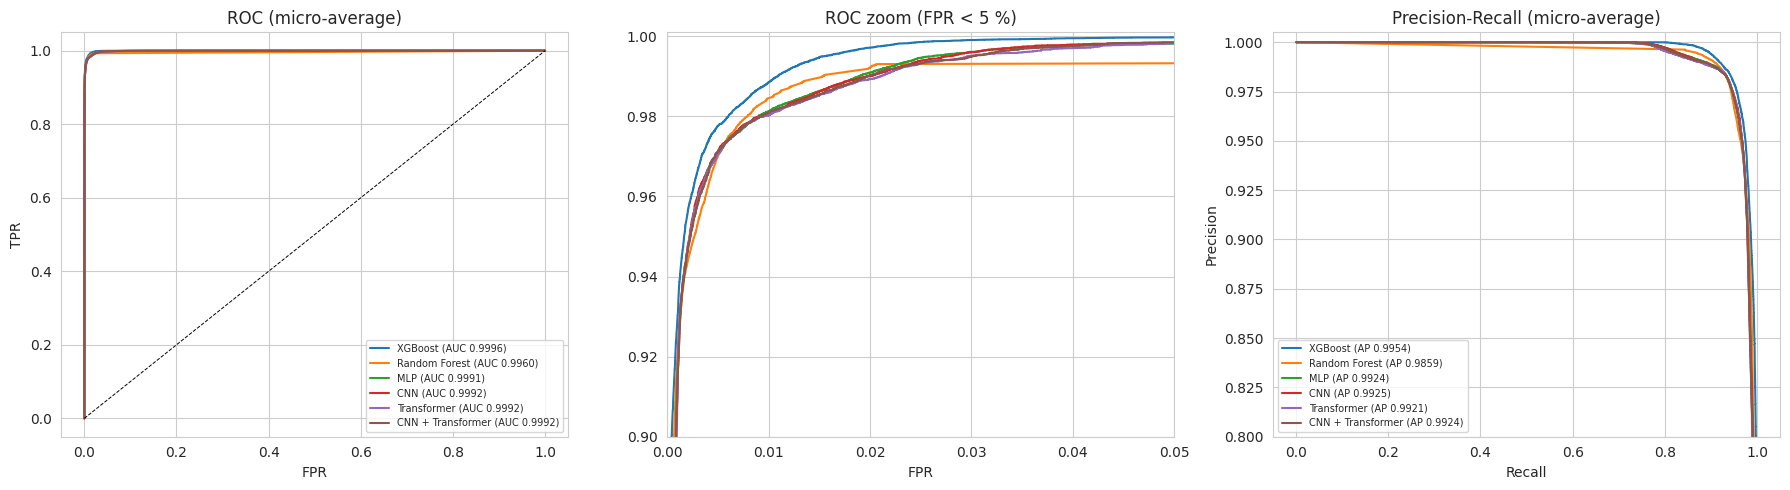

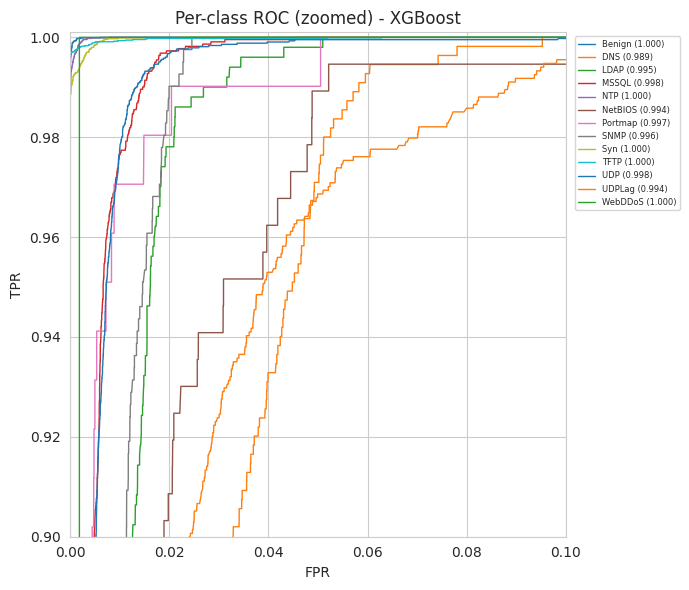

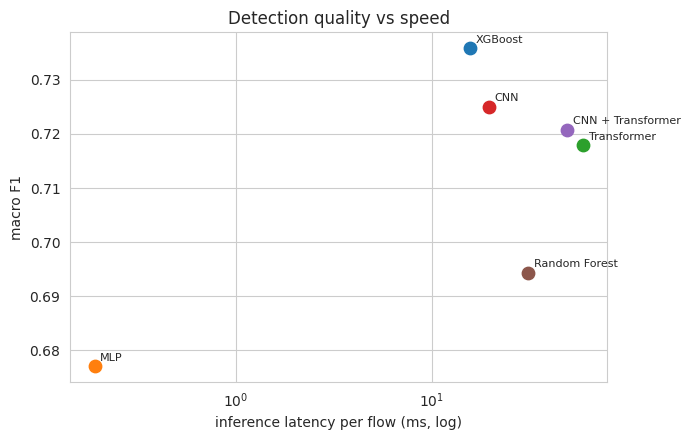

In [14]:
# 8a. Metric comparison charts
cols = ['Accuracy (%)', 'Precision (macro)', 'Recall (macro)', 'F1 (macro)', 'AUC-ROC (macro OvR)']
long = results_df.melt(id_vars='Model', value_vars=[c for c in cols], var_name='Metric', value_name='Value')
long.loc[long.Metric == 'Accuracy (%)', 'Value'] /= 100
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [3, 1]})
sns.barplot(data=long, x='Metric', y='Value', hue='Model', ax=ax[0]); ax[0].set_ylim(max(0, long.Value.min() - 0.03), 1.001)
ax[0].set_title('Accuracy / Precision / Recall / F1 / AUC (higher is better)'); ax[0].legend(fontsize=7, ncol=2)
sns.barplot(data=results_df, y='Model', x='FPR (macro)', ax=ax[1], color='#E45756'); ax[1].set_title('False Positive Rate (lower is better)')
plt.tight_layout(); savefig('metrics_comparison.png'); plt.show()

# 8b. Per-class F1 and FPR heatmaps
fig, ax = plt.subplots(1, 2, figsize=(15, 0.5 * len(reg) + 3))
sns.heatmap(per_class_df.pivot(index='Model', columns='Class', values='F1'), annot=n_classes <= 16, fmt='.2f', cmap='YlGn', vmin=0, vmax=1, ax=ax[0]); ax[0].set_title('Per-class F1')
sns.heatmap(per_class_df.pivot(index='Model', columns='Class', values='FPR'), annot=n_classes <= 16, fmt='.3f', cmap='Reds', ax=ax[1]); ax[1].set_title('Per-class FPR')
plt.tight_layout(); savefig('per_class_f1_fpr.png'); plt.show()

# 8c. Confusion matrices (row-normalised), one figure per model
for n in reg:
    cmn = CMS[n] / np.maximum(CMS[n].sum(1, keepdims=True), 1)
    plt.figure(figsize=(max(7, n_classes * 0.55), max(6, n_classes * 0.5)))
    sns.heatmap(cmn, cmap='Blues', annot=n_classes <= 16, fmt='.2f', annot_kws={'size': 7}, xticklabels=class_names, yticklabels=class_names, vmin=0, vmax=1)
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'Confusion matrix (normalised) - {n}'); plt.tight_layout()
    savefig(f'confusion_{n.replace(" ", "_").replace("+", "plus")}.png'); plt.show()
    pd.DataFrame(CMS[n], index=class_names, columns=class_names).to_csv(os.path.join(TABLE_DIR, f'confusion_counts_{n.replace(" ", "_").replace("+", "plus")}.csv'))

# 8d. ROC and Precision-Recall curves (micro-average over all classes)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for n in reg:
    fp_, tp_, _ = roc_curve(Y_onehot.ravel(), PROBS[n].ravel()); a_ = auc(fp_, tp_)
    ax[0].plot(fp_, tp_, label=f'{n} (AUC {a_:.4f})'); ax[1].plot(fp_, tp_, label=n)
    pr_, rc_, _ = precision_recall_curve(Y_onehot.ravel(), PROBS[n].ravel())
    ax[2].plot(rc_, pr_, label=f'{n} (AP {average_precision_score(Y_onehot.ravel(), PROBS[n].ravel()):.4f})')
ax[0].plot([0, 1], [0, 1], 'k--', lw=.7); ax[0].set_title('ROC (micro-average)'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend(fontsize=7)
ax[1].set_xlim(0, 0.05); ax[1].set_ylim(0.9, 1.001); ax[1].set_title('ROC zoom (FPR < 5 %)'); ax[1].set_xlabel('FPR')
ax[2].set_title('Precision-Recall (micro-average)'); ax[2].set_xlabel('Recall'); ax[2].set_ylabel('Precision'); ax[2].set_ylim(0.8, 1.005); ax[2].legend(fontsize=7)
plt.tight_layout(); savefig('roc_pr_curves.png'); plt.show()

# 8e. Per-class ROC curves of the best model
plt.figure(figsize=(7, 6))
for c in range(n_classes):
    f_, t_, _ = roc_curve(Y_onehot[:, c], PROBS[best_model][:, c]); plt.plot(f_, t_, lw=1, label=f'{class_names[c]} ({auc(f_, t_):.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=.7); plt.xlim(0, 0.1); plt.ylim(0.9, 1.001)
plt.title(f'Per-class ROC (zoomed) - {best_model}'); plt.xlabel('FPR'); plt.ylabel('TPR'); plt.legend(fontsize=6, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); savefig('roc_per_class_best.png'); plt.show()

# 8f. Accuracy vs latency trade-off
plt.figure(figsize=(7, 4.5))
for _, r in results_df.iterrows():
    plt.scatter(r['Inference ms/flow'], r['F1 (macro)'], s=80); plt.annotate(r['Model'], (r['Inference ms/flow'], r['F1 (macro)']), fontsize=8, xytext=(4, 4), textcoords='offset points')
plt.xscale('log'); plt.xlabel('inference latency per flow (ms, log)'); plt.ylabel('macro F1'); plt.title('Detection quality vs speed')
plt.tight_layout(); savefig('accuracy_vs_latency.png'); plt.show()

## 9. Explainable AI (SHAP) for every model
* **XGBoost, Random Forest** -> `shap.TreeExplainer` (exact)
* **CNN, Transformer, CNN+Transformer** -> `shap.GradientExplainer` (automatic fallback to the model-agnostic Permutation explainer if the installed SHAP/TF version is incompatible)
* **MLP** -> model-agnostic Permutation explainer

**Explanation quality** (computed for the predicted class of each explained flow):
* **Faithfulness (deletion test)** - drop in predicted-class probability when the top-k SHAP features are neutralised (set to the training mean), minus the drop when k random features are neutralised. Higher = SHAP really points at what the model uses.
* **Sparsity** - share of total |SHAP| carried by the top-k features. Higher = more concise explanations.
* **Stability** - Spearman rank correlation of global feature importance computed on two disjoint halves of the explained samples. Higher = more reproducible.
* **Explanation time** - seconds / ms per explained flow.

In [15]:
# explained samples: up to SHAP_PER_CLASS per class from the test set; background from train
shap_idx = np.concatenate([rng.choice(np.where(y_te == c)[0], min(SHAP_PER_CLASS, (y_te == c).sum()), replace=False) for c in range(n_classes)])
Xs, ys = X_te[shap_idx], y_te[shap_idx]
Xbg = X_tr[rng.choice(len(X_tr), SHAP_BG, replace=False)]
N_S = len(Xs); print('Explaining', N_S, 'flows with', N_FEAT, 'features each')

def norm_sv(sv, N, F):
    # -> array (N, F, C) whatever the SHAP version returns
    if isinstance(sv, list): sv = np.stack([np.asarray(s).reshape(N, F) for s in sv], axis=-1)
    sv = np.asarray(sv)
    if sv.ndim == 4: sv = sv.reshape(N, F, -1)
    if sv.shape[0] != N: sv = np.moveaxis(sv, 0, -1)
    return sv

def permutation_shap(predict_fn):
    masker = shap.maskers.Independent(Xbg, max_samples=SHAP_BG)
    ex = shap.Explainer(predict_fn, masker, algorithm='permutation')
    return ex(Xs, max_evals=3 * N_FEAT, silent=True).values

def explain(name):
    r = reg[name]; t = time.time(); method = None; sv = None
    if name in ('XGBoost', 'Random Forest'):
        ex = shap.TreeExplainer(r['obj'])
        sv = ex.shap_values(Xs) if name == 'XGBoost' else ex.shap_values(Xs, check_additivity=False)
        method = 'TreeExplainer'
    elif r['type'] == 'dl':
        try:
            ex = shap.GradientExplainer(r['obj'], Xbg[..., None]); sv = ex.shap_values(Xs[..., None]); method = 'GradientExplainer'
        except Exception as e:
            print(f'  GradientExplainer failed for {name} ({type(e).__name__}) -> using Permutation explainer')
    if sv is None:
        sv = permutation_shap(r['predict']); method = method or 'PermutationExplainer'
        if r['type'] == 'dl': method = 'PermutationExplainer (fallback)'
    el = time.time() - t
    return norm_sv(sv, N_S, N_FEAT), method, el

def explanation_quality(sv, predict_fn, k=TOP_K_DELETE):
    P0 = predict_fn(Xs); pred = P0.argmax(1); ar = np.arange(N_S); p0 = P0[ar, pred]
    local = sv[ar, :, pred]                                   # (N, F) attribution of the predicted class
    top = np.argsort(-np.abs(local), axis=1)[:, :k]
    Xt = Xs.copy(); np.put_along_axis(Xt, top, 0.0, axis=1)   # 0 == training mean in scaled space
    drop_top = (p0 - predict_fn(Xt)[ar, pred]).mean()
    rnd = np.stack([rng.choice(N_FEAT, k, replace=False) for _ in range(N_S)])
    Xr = Xs.copy(); np.put_along_axis(Xr, rnd, 0.0, axis=1)
    drop_rnd = (p0 - predict_fn(Xr)[ar, pred]).mean()
    sparsity = (np.sort(np.abs(local), axis=1)[:, ::-1][:, :k].sum(1) / np.maximum(np.abs(local).sum(1), 1e-12)).mean()
    perm = rng.permutation(N_S); h1, h2 = perm[:N_S // 2], perm[N_S // 2:]
    g1, g2 = np.abs(sv[h1]).mean((0, 2)), np.abs(sv[h2]).mean((0, 2))
    stab = spearmanr(g1, g2).correlation
    return {'Faithfulness (drop top-k)': drop_top, 'Drop random-k': drop_rnd, 'Faithfulness gain': drop_top - drop_rnd,
            'Sparsity (top-k share)': sparsity, 'Stability (Spearman)': stab}

SV, xai_rows = {}, []
for n in reg:
    print('Explaining', n, '...')
    try:
        sv, method, el = explain(n)
    except Exception as e:
        print(f'  SHAP failed for {n}: {type(e).__name__}: {e}'); continue
    SV[n] = sv
    q = explanation_quality(sv, reg[n]['predict'])
    xai_rows.append({'Model': n, 'Explainer': method, 'Explain time total (s)': el, 'Explain time (ms/flow)': el / N_S * 1000, **q})
    print(f'  {method}: {el:.1f} s total, {el / N_S * 1000:.1f} ms/flow | faithfulness gain {q["Faithfulness gain"]:.3f} | stability {q["Stability (Spearman)"]:.3f}')

xai_df = pd.DataFrame(xai_rows)
display(xai_df.round(4)); savetab(xai_df.round(5), 'xai_quality_all_models.csv')
np.savez_compressed(os.path.join(SHAP_DIR, 'shap_values.npz'), X=Xs, y=ys, features=np.array(sel_names), classes=np.array(class_names),
                    **{n.replace(' ', '_').replace('+', 'plus'): v.astype('float32') for n, v in SV.items()})

Explaining 127 flows with 28 features each
Explaining XGBoost ...
  TreeExplainer: 2.1 s total, 16.3 ms/flow | faithfulness gain 0.355 | stability 0.999
Explaining Random Forest ...
  TreeExplainer: 72.1 s total, 568.1 ms/flow | faithfulness gain 0.262 | stability 0.992
Explaining MLP ...
  PermutationExplainer: 1.5 s total, 11.8 ms/flow | faithfulness gain 0.444 | stability 0.989
Explaining CNN ...
  GradientExplainer: 25.8 s total, 203.2 ms/flow | faithfulness gain 0.359 | stability 0.996
Explaining Transformer ...
  GradientExplainer: 41.1 s total, 323.5 ms/flow | faithfulness gain 0.416 | stability 0.990
Explaining CNN + Transformer ...
  GradientExplainer: 45.4 s total, 357.3 ms/flow | faithfulness gain 0.408 | stability 0.984


,Model,Explainer,Explain time total (s),Explain time (ms/flow),Faithfulness (drop top-k),Drop random-k,Faithfulness gain,Sparsity (top-k share),Stability (Spearman)
0,XGBoost,TreeExplainer,2.0646,16.2564,0.6226,0.2679,0.3547,0.8792,0.9989
1,Random Forest,TreeExplainer,72.1457,568.0764,0.6295,0.3675,0.2620,0.6710,0.9917
2,MLP,PermutationExplainer,1.4995,11.8071,0.6569,0.2127,0.4441,0.8071,0.9889
3,CNN,GradientExplainer,25.8004,203.1529,0.6227,0.2640,0.3587,0.7377,0.9956
4,Transformer,GradientExplainer,41.0790,323.4567,0.7127,0.2968,0.4159,0.9315,0.9901
5,CNN + Transformer,GradientExplainer,45.3809,357.3296,0.6098,0.2014,0.4084,0.7858,0.9840


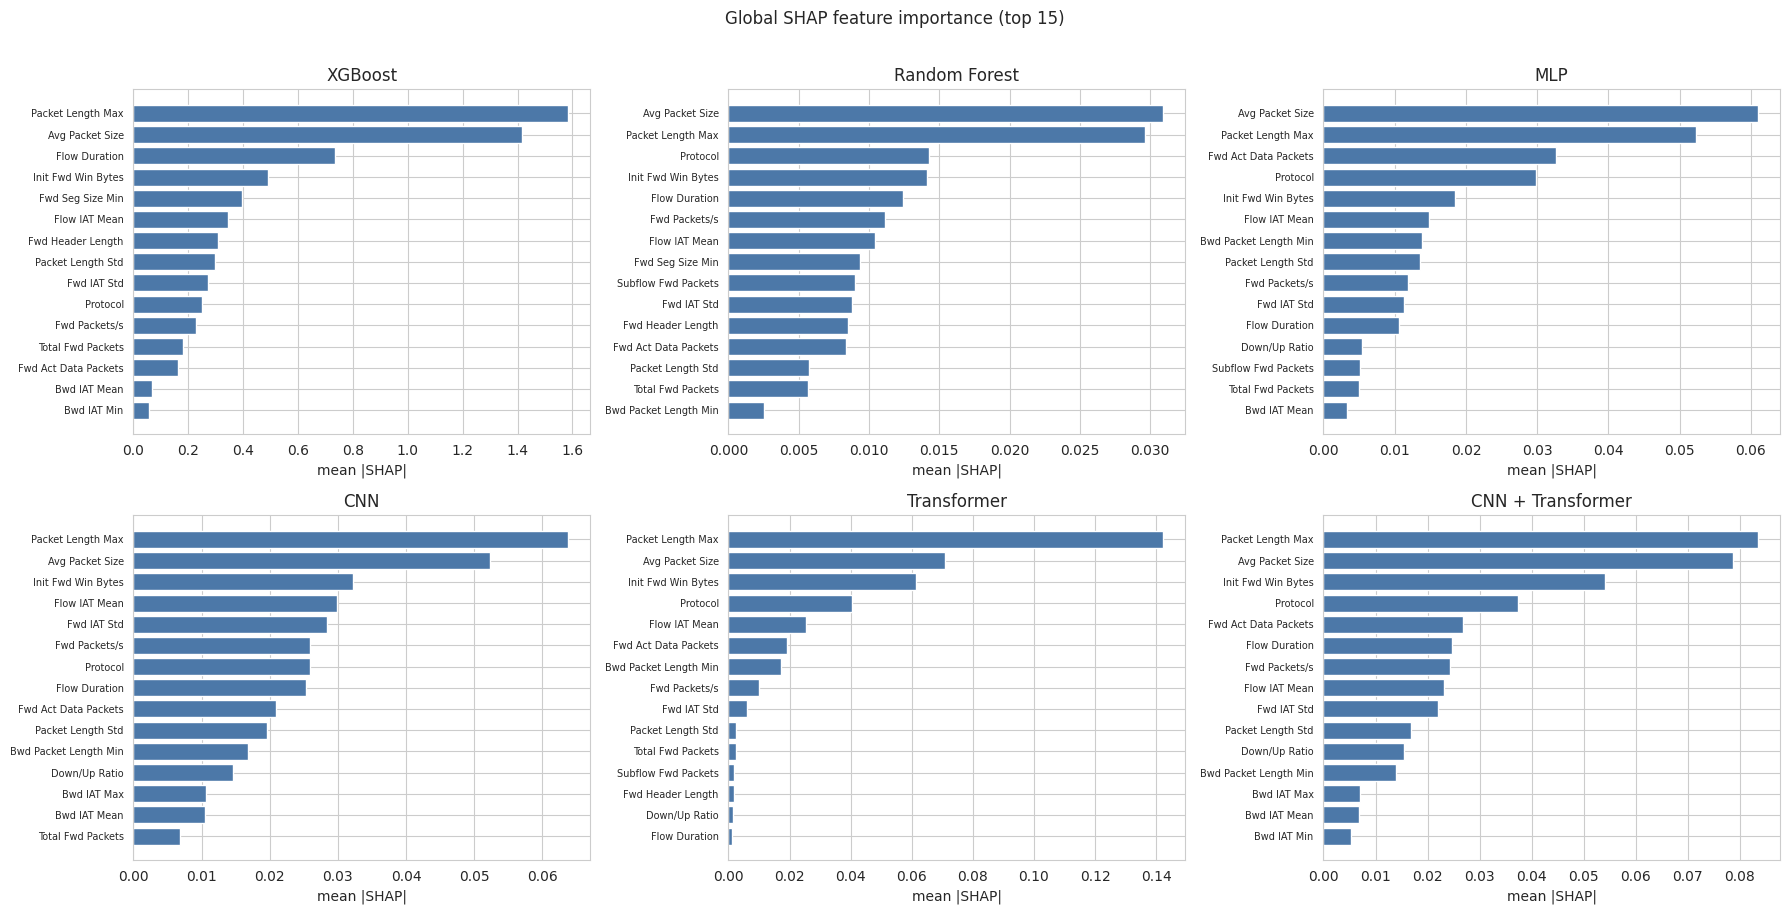

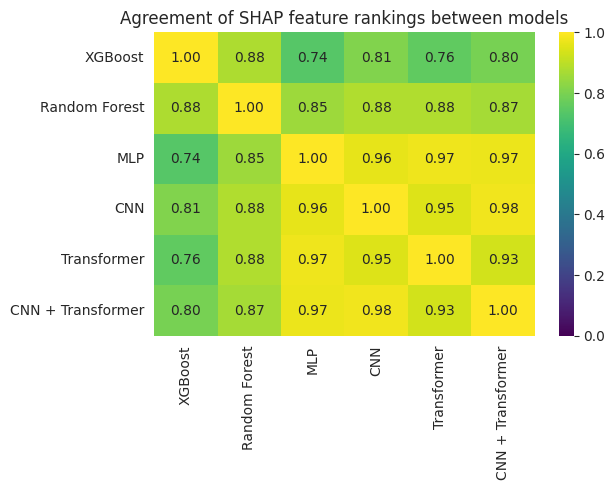

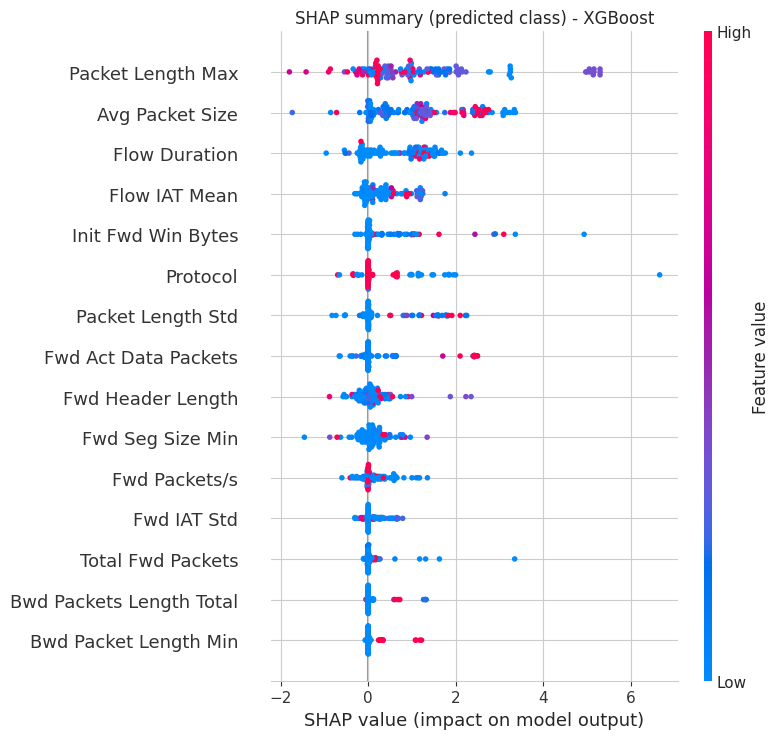

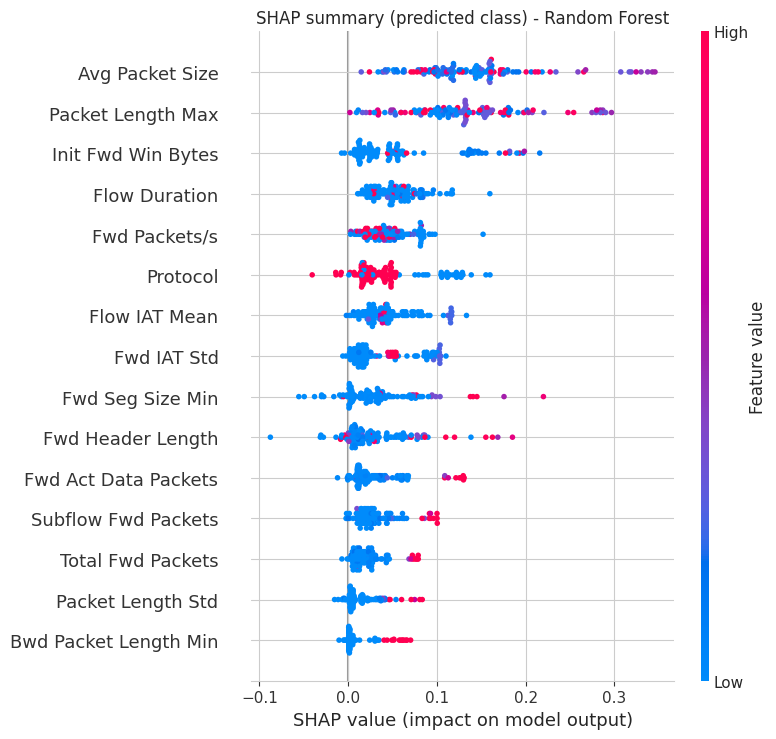

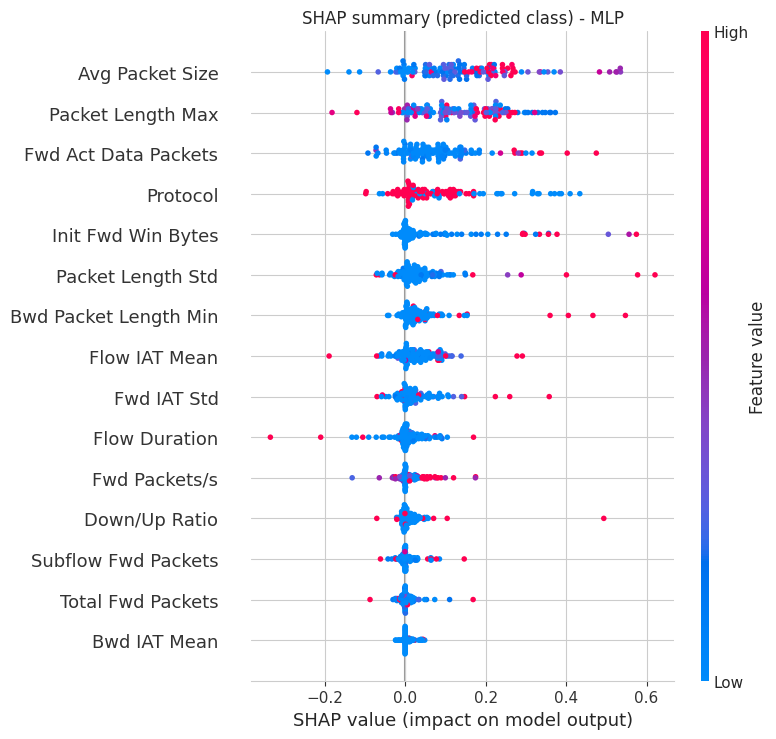

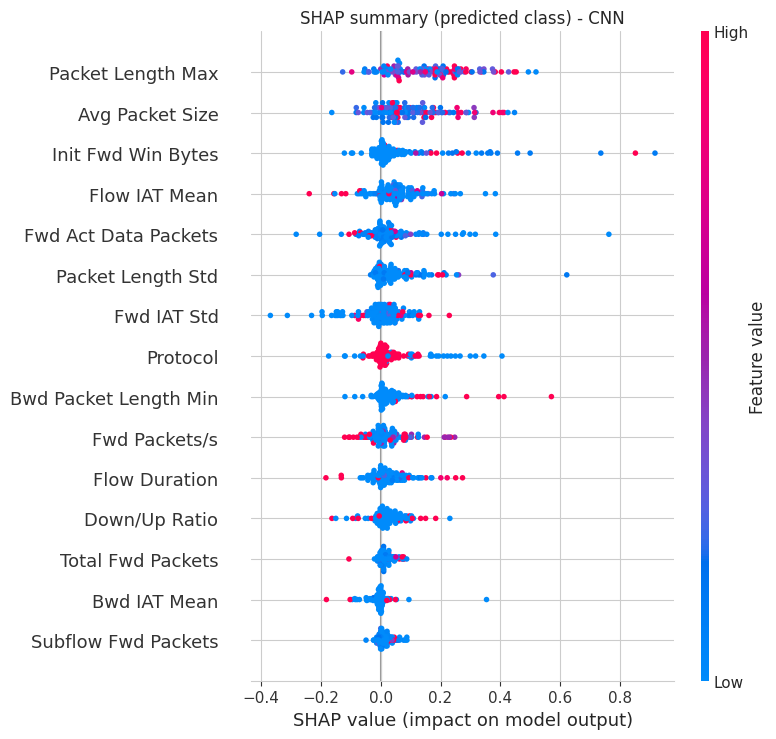

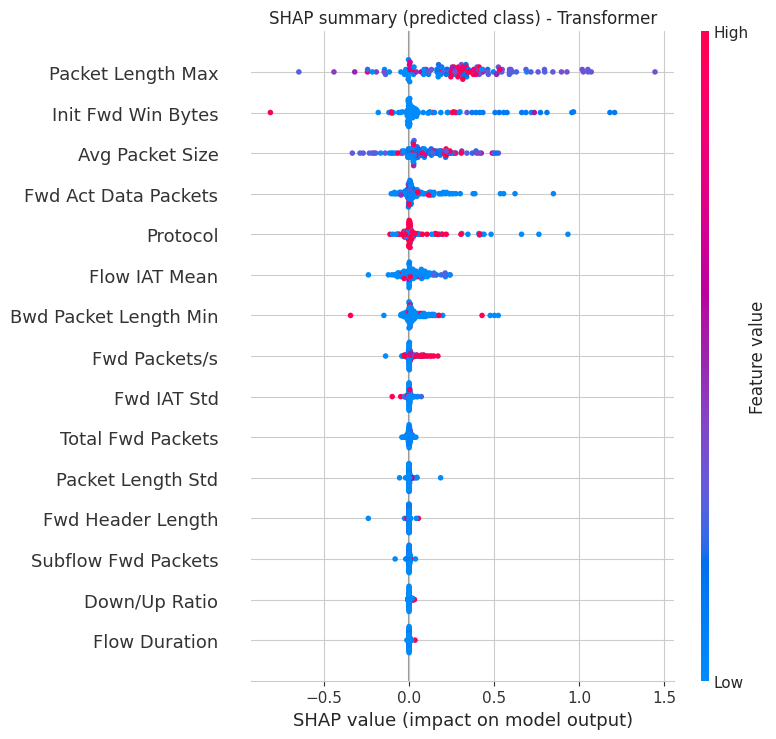

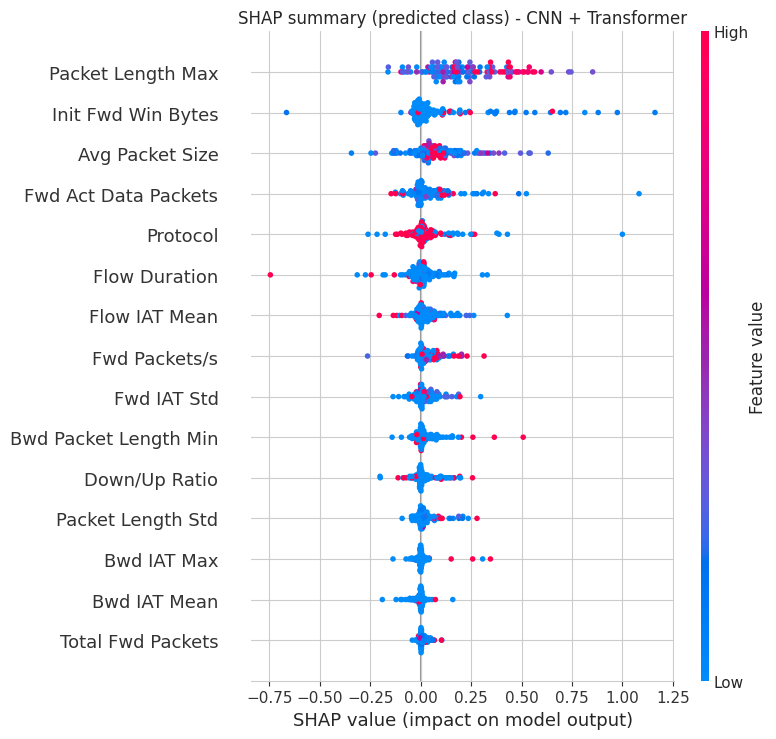

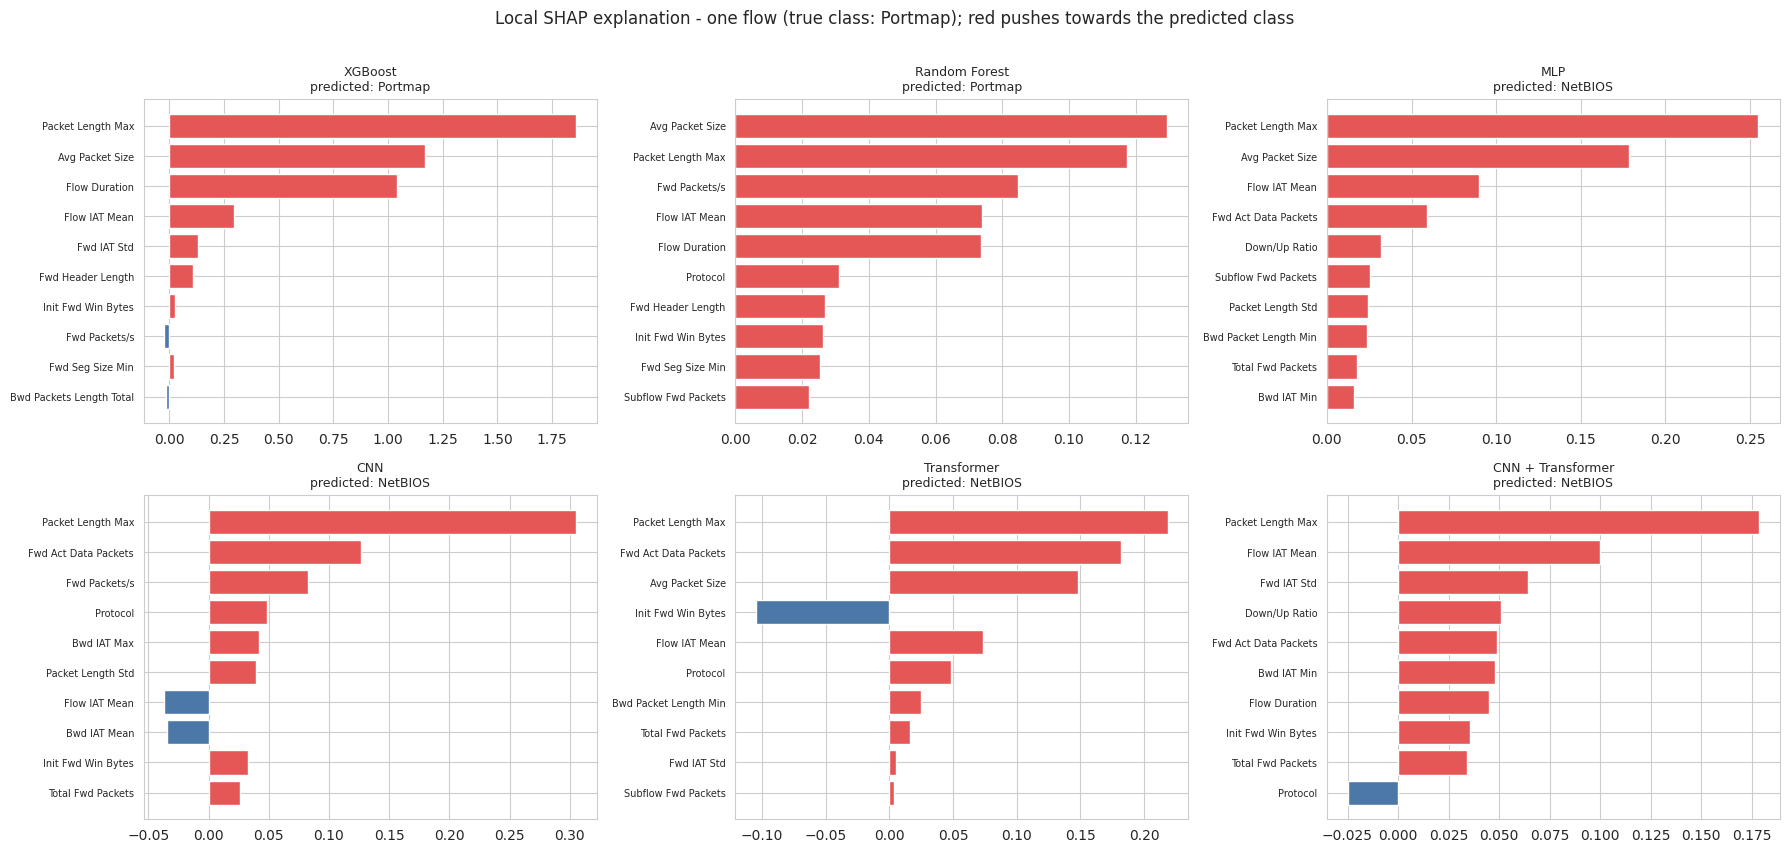

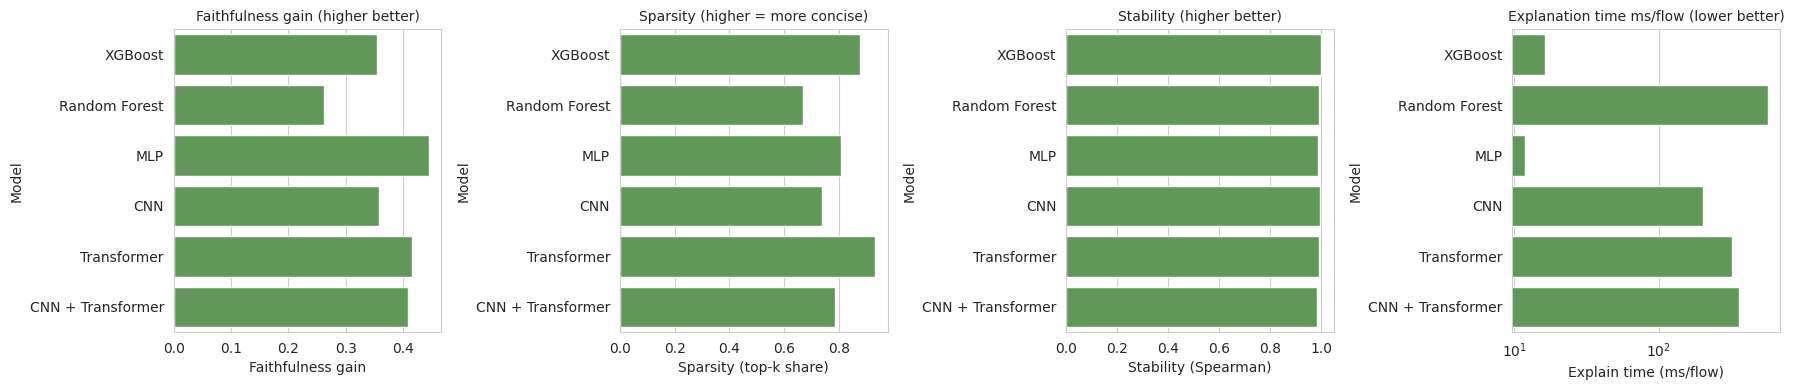

In [16]:
# 9a. Global importance: mean |SHAP| per feature (top 15) for every model
names = list(SV)
imp = {n: np.abs(SV[n]).mean((0, 2)) for n in names}
imp_df = pd.DataFrame(imp, index=sel_names); savetab(imp_df.round(6), 'shap_global_importance.csv', index=True)
cols_n = 3; rows_n = int(np.ceil(len(names) / cols_n))
fig, axs = plt.subplots(rows_n, cols_n, figsize=(6 * cols_n, 4.5 * rows_n)); axs = np.atleast_1d(axs).ravel()
for ax, n in zip(axs, names):
    s = imp_df[n].sort_values().tail(15)
    ax.barh(s.index, s.values, color='#4C78A8'); ax.set_title(f'{n}'); ax.set_xlabel('mean |SHAP|'); ax.tick_params(axis='y', labelsize=7)
for ax in axs[len(names):]: ax.axis('off')
plt.suptitle('Global SHAP feature importance (top 15)', y=1.01); plt.tight_layout(); savefig('shap_global_importance.png'); plt.show()

# 9b. Do the models agree on what matters? (Spearman of global importance)
agree = imp_df.corr(method='spearman')
plt.figure(figsize=(6.5, 5)); sns.heatmap(agree, annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1)
plt.title('Agreement of SHAP feature rankings between models'); plt.tight_layout(); savefig('shap_model_agreement.png'); plt.show()

# 9c. Beeswarm (predicted-class attribution) for every model
for n in names:
    P0 = reg[n]['predict'](Xs).argmax(1); local = SV[n][np.arange(N_S), :, P0]
    shap.summary_plot(local, Xs, feature_names=sel_names, max_display=15, show=False)
    plt.title(f'SHAP summary (predicted class) - {n}'); plt.tight_layout()
    savefig(f'shap_beeswarm_{n.replace(" ", "_").replace("+", "plus")}.png'); plt.show()

# 9d. Local explanation of one attack flow, side by side for all models
cand = [i for i in range(N_S) if not (benign and ys[i] == benign[0])]
li = cand[len(cand) // 2] if cand else 0
fig, axs = plt.subplots(rows_n, cols_n, figsize=(6 * cols_n, 4.2 * rows_n)); axs = np.atleast_1d(axs).ravel()
for ax, n in zip(axs, names):
    pc_ = reg[n]['predict'](Xs[li:li + 1]).argmax(1)[0]
    v = pd.Series(SV[n][li, :, pc_], index=sel_names); v = v.reindex(v.abs().sort_values().tail(10).index)
    ax.barh(v.index, v.values, color=np.where(v.values > 0, '#E45756', '#4C78A8'))
    ax.set_title(f'{n}\npredicted: {class_names[pc_]}', fontsize=9); ax.tick_params(axis='y', labelsize=7)
for ax in axs[len(names):]: ax.axis('off')
plt.suptitle(f'Local SHAP explanation - one flow (true class: {class_names[ys[li]]}); red pushes towards the predicted class', y=1.01)
plt.tight_layout(); savefig('shap_local_explanation.png'); plt.show()

# 9e. Explanation quality charts
if len(xai_df):
    fig, ax = plt.subplots(1, 4, figsize=(18, 4))
    for a, (col, ttl) in zip(ax, [('Faithfulness gain', 'Faithfulness gain (higher better)'), ('Sparsity (top-k share)', 'Sparsity (higher = more concise)'),
                                  ('Stability (Spearman)', 'Stability (higher better)'), ('Explain time (ms/flow)', 'Explanation time ms/flow (lower better)')]):
        sns.barplot(data=xai_df, y='Model', x=col, ax=a, color='#59A14F'); a.set_title(ttl, fontsize=10)
        if col == 'Explain time (ms/flow)': a.set_xscale('log')
    plt.tight_layout(); savefig('shap_quality.png'); plt.show()

## 10. Final report and saved files

In [17]:
final = results_df.merge(xai_df, on='Model', how='left')
display(final.round(4)); savetab(final.round(5), 'FINAL_REPORT.csv')

cfg = dict(n_classes=n_classes, classes=class_names, n_features_all=len(feat_cols), n_features_pso=int(N_FEAT), selected_features=sel_names,
           max_per_class=MAX_PER_CLASS, seed=SEED, pso=dict(particles=PSO_PARTICLES, iters=PSO_ITERS, alpha=PSO_ALPHA, time_s=pso_time),
           dl=dict(batch=BATCH_SIZE, epochs=EPOCHS, d_model=D_MODEL, heads=N_HEADS, blocks=N_BLOCKS, ff=FF_DIM), best_model_f1_macro=best_model)
json.dump(cfg, open(os.path.join(OUT_DIR, 'run_config.json'), 'w'), indent=2)

print('Saved to', OUT_DIR)
for root, _, fs in os.walk(OUT_DIR):
    for f in sorted(fs): print(' ', os.path.relpath(os.path.join(root, f), OUT_DIR), f'({os.path.getsize(os.path.join(root, f)) / 1e6:.1f} MB)')

# --- how to reload a saved deep model later ---
# m = keras.models.load_model(os.path.join(MODEL_DIR, 'xids_cnn_transformer.keras'), custom_objects={'PositionEmbedding': PositionEmbedding})
# sk = joblib.load(os.path.join(MODEL_DIR, 'xgboost.joblib'))
# new flow: scaler_all_features -> clip(-10,10) -> keep selected_features.pkl columns -> model

,Model,Accuracy (%),Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),FPR (macro),AUC-ROC (macro OvR),...,Binary detection rate (%),Binary FPR (%),Explainer,Explain time total (s),Explain time (ms/flow),Faithfulness (drop top-k),Drop random-k,Faithfulness gain,Sparsity (top-k share),Stability (Spearman)
0,XGBoost,96.4855,0.7339,0.7401,0.7358,0.9652,0.9649,0.9648,0.0028,0.9969,...,99.9400,0.1111,TreeExplainer,2.0646,16.2564,0.6226,0.2679,0.3547,0.8792,0.9989
1,MLP,96.1468,0.7055,0.6894,0.6771,0.9608,0.9615,0.9586,0.0031,0.9928,...,99.7971,0.4667,PermutationExplainer,1.4995,11.8071,0.6569,0.2127,0.4441,0.8071,0.9889
2,Transformer,96.1331,0.7366,0.7426,0.7179,0.9624,0.9613,0.9595,0.0031,0.9938,...,99.7228,0.3444,GradientExplainer,41.0790,323.4567,0.7127,0.2968,0.4159,0.9315,0.9901
3,CNN,96.1036,0.7254,0.7495,0.7250,0.9617,0.9610,0.9598,0.0032,0.9946,...,99.7999,0.4333,GradientExplainer,25.8004,203.1529,0.6227,0.2640,0.3587,0.7377,0.9956
4,CNN + Transformer,96.0558,0.7288,0.7445,0.7208,0.9614,0.9606,0.9590,0.0032,0.9948,...,99.7914,0.3778,GradientExplainer,45.3809,357.3296,0.6098,0.2014,0.4084,0.7858,0.9840
5,Random Forest,95.7580,0.6924,0.6967,0.6943,0.9577,0.9576,0.9576,0.0034,0.9708,...,99.8971,0.1778,TreeExplainer,72.1457,568.0764,0.6295,0.3675,0.2620,0.6710,0.9917


Saved to /content/drive/MyDrive/XIDS/output_v2
  run_config.json (0.0 MB)
  models/all_feature_columns.pkl (0.0 MB)
  models/best_xids_cnn.keras (0.7 MB)
  models/best_xids_cnn_transformer.keras (1.2 MB)
  models/best_xids_transformer.keras (1.1 MB)
  models/dl_histories.joblib (0.0 MB)
  models/label_encoder.joblib (0.0 MB)
  models/mlp.joblib (0.1 MB)
  models/pso_selected_mask.pkl (0.0 MB)
  models/random_forest.joblib (39.3 MB)
  models/scaler_all_features.joblib (0.0 MB)
  models/selected_features.pkl (0.0 MB)
  models/xgboost.joblib (5.6 MB)
  models/xids_cnn.keras (0.7 MB)
  models/xids_cnn_transformer.keras (1.2 MB)
  models/xids_transformer.keras (1.1 MB)
  plots/accuracy_vs_latency.png (0.0 MB)
  plots/confusion_CNN.png (0.1 MB)
  plots/confusion_CNN_plus_Transformer.png (0.1 MB)
  plots/confusion_MLP.png (0.1 MB)
  plots/confusion_Random_Forest.png (0.1 MB)
  plots/confusion_Transformer.png (0.1 MB)
  plots/confusion_XGBoost.png (0.1 MB)
  plots/insight_capping.png (0.1 MB)


In [18]:
# Save predictions and SHAP values directly as CSVs/joblib files instead of compressed .npz archives
import joblib
import os

# 1. Save test probabilities directly as a CSV
probs_df = pd.DataFrame(columns=['True_Label'])
probs_df['True_Label'] = [class_names[y] for y in y_te]
for n, p in PROBS.items():
    col_names = [f"{n}_{c}" for c in class_names]
    probs_df[col_names] = p
savetab(probs_df, 'test_probabilities_direct.csv', index=False)
print("Saved direct test probabilities to test_probabilities_direct.csv")

# 2. Save SHAP values directly as a dictionary using joblib (uncompressed direct file)
shap_direct_path = os.path.join(SHAP_DIR, 'shap_values_direct.joblib')
joblib.dump({
    'X': Xs,
    'y': ys,
    'features': sel_names,
    'classes': class_names,
    'shap_values': SV
}, shap_direct_path, compress=0)
print(f"Saved direct SHAP values to: {shap_direct_path}")

Saved direct test probabilities to test_probabilities_direct.csv
Saved direct SHAP values to: /content/drive/MyDrive/XIDS/output_v2/shap/shap_values_direct.joblib


In [19]:
import os
import pandas as pd
import joblib

# 1. Create a dedicated directory for direct files
DIRECT_DIR = os.path.join(OUT_DIR, 'direct_output')
os.makedirs(DIRECT_DIR, exist_ok=True)
print(f"Created directory: {DIRECT_DIR}")

# 2. Save test ground truth labels and model probabilities as direct CSV files
# Save ground truth first
labels_df = pd.DataFrame({'true_label_idx': y_te, 'true_label_name': [class_names[i] for i in y_te]})
labels_df.to_csv(os.path.join(DIRECT_DIR, 'test_ground_truth.csv'), index=False)
print("Saved test_ground_truth.csv")

# Save probabilities for each model individually
for name, prob in PROBS.items():
    safe_name = name.lower().replace(' ', '_').replace('+', 'plus')
    prob_df = pd.DataFrame(prob, columns=[f"prob_{c}" for c in class_names])
    prob_df.to_csv(os.path.join(DIRECT_DIR, f'probabilities_{safe_name}.csv'), index=False)
    print(f"Saved probabilities_{safe_name}.csv")

# 3. Save XAI/SHAP outputs directly as uncompressed joblib and CSV files
# Save features, classes, background and test matrices
joblib.dump({
    'feature_names': sel_names,
    'class_names': class_names,
    'X_test_explained': Xs,
    'y_test_explained': ys
}, os.path.join(DIRECT_DIR, 'shap_metadata.joblib'), compress=0)
print("Saved shap_metadata.joblib (uncompressed)")

# Save raw SHAP values for each model as separate uncompressed files
for name, sv in SV.items():
    safe_name = name.lower().replace(' ', '_').replace('+', 'plus')
    joblib.dump(sv, os.path.join(DIRECT_DIR, f'shap_values_{safe_name}.joblib'), compress=0)
    print(f"Saved shap_values_{safe_name}.joblib (uncompressed)")

print("\nAll items successfully exported to direct_output!")

Created directory: /content/drive/MyDrive/XIDS/output_v2/direct_output
Saved test_ground_truth.csv
Saved probabilities_xgboost.csv
Saved probabilities_random_forest.csv
Saved probabilities_mlp.csv
Saved probabilities_cnn.csv
Saved probabilities_transformer.csv
Saved probabilities_cnn_plus_transformer.csv
Saved shap_metadata.joblib (uncompressed)
Saved shap_values_xgboost.joblib (uncompressed)
Saved shap_values_random_forest.joblib (uncompressed)
Saved shap_values_mlp.joblib (uncompressed)
Saved shap_values_cnn.joblib (uncompressed)
Saved shap_values_transformer.joblib (uncompressed)
Saved shap_values_cnn_plus_transformer.joblib (uncompressed)

All items successfully exported to direct_output!
